In [1]:

from pathlib import Path
from collections import Counter
import sys
import torch

DATA_ROOT = Path("/kaggle/input")

# Hardware
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

# Dataset discovery
csv_files = sorted(DATA_ROOT.rglob("*.csv"))
jpg_files = sorted(DATA_ROOT.rglob("*.jpg"))

print("\nCSV files found:", len(csv_files))
print("JPG images found:", len(jpg_files))

print("\nAnnotation files:")
for path in csv_files:
    print(path)
    with path.open("r", encoding="utf-8-sig") as f:
        for _ in range(2):
            line = f.readline().strip()
            if line:
                print("  ", line[:180])

print("\nImage directories:")
for folder, count in Counter(
    str(p.parent) for p in jpg_files
).most_common(10):
    print(f"{count:>6} images | {folder}")

print("\nExample image paths:")
for path in jpg_files[:3]:
    print(path)


Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA available: True
GPU 0: Tesla T4
GPU 1: Tesla T4

CSV files found: 3
JPG images found: 11743

Annotation files:
/kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/annotations/annotations_test.csv
   test_0.jpg,120,2527,225,2764,object,2448,3264
   test_0.jpg,727,2269,862,2376,object,2448,3264
/kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/annotations/annotations_train.csv
   train_0.jpg,208,537,422,814,object,3024,3024
   train_0.jpg,1268,1923,1365,2209,object,3024,3024
/kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/annotations/annotations_val.csv
   val_0.jpg,5,1429,219,1612,object,2336,4160
   val_0.jpg,467,1066,589,1330,object,2336,4160

Image directories:
 11743 images | /kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/images

Example image paths:
/kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/images/test_0.jpg
/kaggle/input/datasets/mohamedessam3112002

In [2]:

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

IMG_DIR = ROOT / "images"
ANN_DIR = ROOT / "annotations"

COLUMNS = [
    "image_name", "x1", "y1", "x2", "y2",
    "class", "image_width", "image_height"
]

available_images = {p.name for p in IMG_DIR.glob("*.jpg")}
split_images = set()

for split in ["train", "val", "test"]:

    csv_path = ANN_DIR / f"annotations_{split}.csv"

    df = pd.read_csv(
        csv_path,
        header=None,
        names=COLUMNS
    )

    counts = df.groupby("image_name").size()
    names = set(df["image_name"])

    invalid = (
        (df["x1"] < 0) |
        (df["y1"] < 0) |
        (df["x2"] <= df["x1"]) |
        (df["y2"] <= df["y1"]) |
        (df["x2"] > df["image_width"]) |
        (df["y2"] > df["image_height"])
    )

    print(f"\n{'=' * 45}")
    print(f"SPLIT: {split.upper()}")
    print(f"{'=' * 45}")

    print("Images annotated:", len(names))
    print("Total bounding boxes:", len(df))
    print("Classes:", df["class"].unique())
    print("Missing images:", len(names - available_images))
    print("Invalid boxes:", int(invalid.sum()))
    print("Overlap with earlier splits:",
          len(names & split_images))

    print("\nProducts per image:")
    print(counts.describe().round(2))

    split_images.update(names)

print("\n" + "=" * 45)
print("DATASET SUMMARY")
print("=" * 45)
print("Total JPG images:", len(available_images))
print("Unique annotated images:", len(split_images))
print("Unannotated images:",
      len(available_images - split_images))



SPLIT: TRAIN
Images annotated: 8219
Total bounding boxes: 1208482
Classes: ['object']
Missing images: 0
Invalid boxes: 14918
Overlap with earlier splits: 0

Products per image:
count    8219.00
mean      147.04
std        42.76
min         1.00
25%       123.00
50%       138.00
75%       161.00
max       576.00
dtype: float64

SPLIT: VAL
Images annotated: 588
Total bounding boxes: 90968
Classes: ['object']
Missing images: 0
Invalid boxes: 1031
Overlap with earlier splits: 0

Products per image:
count    588.00
mean     154.71
std       59.92
min       40.00
25%      124.00
50%      139.00
75%      167.25
max      718.00
dtype: float64

SPLIT: TEST
Images annotated: 2936
Total bounding boxes: 431546
Classes: ['object']
Missing images: 0
Invalid boxes: 5211
Overlap with earlier splits: 0

Products per image:
count    2936.00
mean      146.98
std        41.39
min        20.00
25%       123.00
50%       137.00
75%       161.00
max       533.00
dtype: float64

DATASET SUMMARY
Total JPG ima

In [3]:

import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from IPython.display import display

ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

columns = [
    "image_name", "x1", "y1", "x2", "y2",
    "class", "image_width", "image_height"
]

df = pd.read_csv(
    ROOT / "annotations/annotations_train.csv",
    header=None,
    names=columns
)

# Identify the individual reasons boxes were flagged.
checks = {
    "Negative x1": df["x1"] < 0,
    "Negative y1": df["y1"] < 0,
    "Non-positive width": df["x2"] <= df["x1"],
    "Non-positive height": df["y2"] <= df["y1"],
    "x2 exceeds image width":
        df["x2"] > df["image_width"],
    "y2 exceeds image height":
        df["y2"] > df["image_height"],
}

invalid = pd.DataFrame(checks).any(axis=1)

print("INVALID BOX BREAKDOWN")
print("=" * 45)

for reason, condition in checks.items():
    print(f"{reason:<30} {condition.sum():>8,}")

print("\nTotal unique flagged boxes:", invalid.sum())

# Check whether clipping to the image boundaries
# would leave a nonzero-area rectangle.
x1_clip = np.maximum(df["x1"], 0)
y1_clip = np.maximum(df["y1"], 0)

x2_clip = np.minimum(
    df["x2"], df["image_width"]
)
y2_clip = np.minimum(
    df["y2"], df["image_height"]
)

geometrically_clippable = (
    (x2_clip > x1_clip) &
    (y2_clip > y1_clip)
)

print(
    "Flagged boxes with positive area after clipping:",
    (invalid & geometrically_clippable).sum()
)
print(
    "Flagged boxes not recoverable by simple clipping:",
    (invalid & ~geometrically_clippable).sum()
)

# Inspect examples of flagged annotations.
print("\nSAMPLE FLAGGED ANNOTATIONS")

sample = df.loc[invalid].sample(
    n=min(12, int(invalid.sum())),
    random_state=42
)

display(sample)

# Check the true image dimensions against CSV metadata.
print("\nIMAGE DIMENSION VERIFICATION")

names = sample["image_name"].unique()
mismatches = 0

for name in names:
    row = df[df["image_name"] == name].iloc[0]

    with Image.open(ROOT / "images" / name) as im:
        actual_w, actual_h = im.size

    csv_w = int(row["image_width"])
    csv_h = int(row["image_height"])

    match = (actual_w == csv_w and actual_h == csv_h)
    mismatches += not match

    print(
        f"{name}: CSV=({csv_w},{csv_h}), "
        f"Actual=({actual_w},{actual_h}), "
        f"Match={match}"
    )

print("\nDimension mismatches in sample:", mismatches)


INVALID BOX BREAKDOWN
Negative x1                           0
Negative y1                           0
Non-positive width                    0
Non-positive height                   0
x2 exceeds image width           13,317
y2 exceeds image height           1,628

Total unique flagged boxes: 14918
Flagged boxes with positive area after clipping: 14918
Flagged boxes not recoverable by simple clipping: 0

SAMPLE FLAGGED ANNOTATIONS


,image_name,x1,y1,x2,y2,class,image_width,image_height
666215,train_5086.jpg,2237,2227,2342,2417,object,2340,4160
293231,train_2801.jpg,2092,494,2449,584,object,2448,3264
1094470,train_7714.jpg,2388,467,2451,817,object,2448,3264
411851,train_3535.jpg,2356,2911,2449,3047,object,2448,3264
785758,train_5825.jpg,2087,2077,2164,2405,object,2160,3840
280673,train_2724.jpg,1847,2345,1922,2541,object,1920,2560
645926,train_4961.jpg,1872,1498,1922,1653,object,1920,2560
246466,train_2517.jpg,2063,3100,2345,3363,object,2340,4160
592571,train_4638.jpg,2380,411,2450,681,object,2448,3264
839721,train_6161.jpg,2652,3939,2776,4211,object,3120,4208



IMAGE DIMENSION VERIFICATION
train_5086.jpg: CSV=(2340,4160), Actual=(2340,4160), Match=True
train_2801.jpg: CSV=(2448,3264), Actual=(2448,3264), Match=True
train_7714.jpg: CSV=(2448,3264), Actual=(2448,3264), Match=True
train_3535.jpg: CSV=(2448,3264), Actual=(2448,3264), Match=True
train_5825.jpg: CSV=(2160,3840), Actual=(2160,3840), Match=True
train_2724.jpg: CSV=(1920,2560), Actual=(1920,2560), Match=True
train_4961.jpg: CSV=(1920,2560), Actual=(1920,2560), Match=True
train_2517.jpg: CSV=(2340,4160), Actual=(2340,4160), Match=True
train_4638.jpg: CSV=(2448,3264), Actual=(2448,3264), Match=True
train_6161.jpg: CSV=(3120,4208), Actual=(3120,4208), Match=True
train_6266.jpg: CSV=(2448,3264), Actual=(2448,3264), Match=True
train_3121.jpg: CSV=(2336,4160), Actual=(2336,4160), Match=True

Dimension mismatches in sample: 0


In [4]:

import numpy as np
import pandas as pd
from IPython.display import display

# Calculate boundary overflow in pixels
x_overflow = (df["x2"] - df["image_width"]).clip(lower=0)
y_overflow = (df["y2"] - df["image_height"]).clip(lower=0)

# Original bounding-box area
original_area = (
    (df["x2"] - df["x1"]) *
    (df["y2"] - df["y1"])
)

# Coordinates after clipping
x2_clipped = np.minimum(df["x2"], df["image_width"])
y2_clipped = np.minimum(df["y2"], df["image_height"])

clipped_area = (
    (x2_clipped - df["x1"]) *
    (y2_clipped - df["y1"])
)

# Percentage of original area lost
area_loss_pct = (
    (1 - clipped_area / original_area) * 100
)

flagged = (x_overflow > 0) | (y_overflow > 0)

print("BOUNDARY OVERFLOW STATISTICS")
print("=" * 45)

for name, values in [
    ("Horizontal overflow", x_overflow),
    ("Vertical overflow", y_overflow)
]:
    nonzero = values[values > 0]

    print(f"\n{name} (pixels):")
    print(
        nonzero.describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        ).round(2)
    )

print("\nAREA LOST AFTER CLIPPING (%)")
print("=" * 45)

print(
    area_loss_pct[flagged].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(3)
)

print("\nSEVERITY BREAKDOWN")

for threshold in [1, 5, 10, 25, 50]:
    count = (
        area_loss_pct[flagged] > threshold
    ).sum()

    print(f"Area loss > {threshold}%: {count:,}")

# Investigate worst cases
diagnostics = df.loc[flagged].copy()

diagnostics["x_overflow"] = x_overflow[flagged]
diagnostics["y_overflow"] = y_overflow[flagged]
diagnostics["area_loss_pct"] = area_loss_pct[flagged]

print("\n10 MOST SEVERELY AFFECTED ANNOTATIONS")

display(
    diagnostics.sort_values(
        "area_loss_pct", ascending=False
    ).head(10).round(3)
)


BOUNDARY OVERFLOW STATISTICS

Horizontal overflow (pixels):
count    13317.00
mean         2.04
std          1.12
min          1.00
50%          2.00
90%          4.00
95%          4.00
99%          5.00
max          9.00
dtype: float64

Vertical overflow (pixels):
count    1628.00
mean        1.82
std         0.86
min         1.00
50%         2.00
90%         3.00
95%         3.00
99%         4.00
max         5.00
dtype: float64

AREA LOST AFTER CLIPPING (%)
count    14918.000
mean         1.915
std          1.519
min          0.060
50%          1.471
90%          3.810
95%          4.902
99%          7.407
max         22.727
dtype: float64

SEVERITY BREAKDOWN
Area loss > 1%: 10,408
Area loss > 5%: 719
Area loss > 10%: 29
Area loss > 25%: 0
Area loss > 50%: 0

10 MOST SEVERELY AFFECTED ANNOTATIONS


,image_name,x1,y1,x2,y2,class,image_width,image_height,x_overflow,y_overflow,area_loss_pct
230547,train_242.jpg,2431,1875,2453,1996,object,2448,3264,5,0,22.727
903194,train_6554.jpg,2312,3051,2341,3195,object,2336,4160,5,0,17.241
359031,train_3211.jpg,2307,1659,2342,1911,object,2336,4160,6,0,17.143
985483,train_7058.jpg,2427,1388,2452,1607,object,2448,3264,4,0,16.000
555550,train_4411.jpg,2302,1825,2342,2169,object,2336,4160,6,0,15.000
302834,train_2863.jpg,2424,1750,2452,2062,object,2448,3264,4,0,14.286
584466,train_4587.jpg,2424,1732,2452,2023,object,2448,3264,4,0,14.286
826976,train_6080.jpg,2315,2354,2344,2552,object,2340,4160,4,0,13.793
546998,train_436.jpg,2304,3100,2341,3213,object,2336,4160,5,0,13.514
895232,train_6502.jpg,2290,1877,2343,2091,object,2336,4160,7,0,13.208


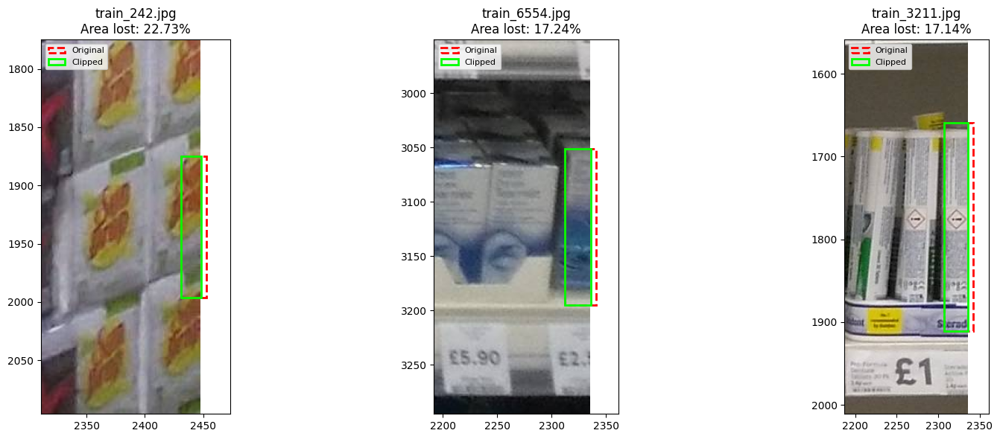

In [5]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

worst_boxes = diagnostics.sort_values(
    "area_loss_pct",
    ascending=False
).head(3)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 6)
)

for ax, (_, row) in zip(
    axes, worst_boxes.iterrows()
):
    image_path = ROOT / "images" / row["image_name"]

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    W, H = image.size

    x1, y1, x2, y2 = [
        float(row[c])
        for c in ["x1", "y1", "x2", "y2"]
    ]

    # Original annotation
    original_box = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        edgecolor="red",
        facecolor="none",
        linewidth=2,
        linestyle="--",
        label="Original"
    )

    # Clipped annotation
    clipped_box = Rectangle(
        (x1, y1),
        min(x2, W) - x1,
        min(y2, H) - y1,
        edgecolor="lime",
        facecolor="none",
        linewidth=2,
        label="Clipped"
    )

    ax.imshow(image)
    ax.add_patch(original_box)
    ax.add_patch(clipped_box)

    # Zoom into the affected image boundary
    ax.set_xlim(
        max(0, x1 - 120),
        min(W, x2) + 25
    )

    ax.set_ylim(
        min(H, y2 + 100),
        max(0, y1 - 100)
    )

    ax.set_title(
        f"{row['image_name']}\n"
        f"Area lost: {row['area_loss_pct']:.2f}%"
    )

    ax.legend(loc="upper left", fontsize=8)
    ax.grid(False)

plt.tight_layout()
plt.show()


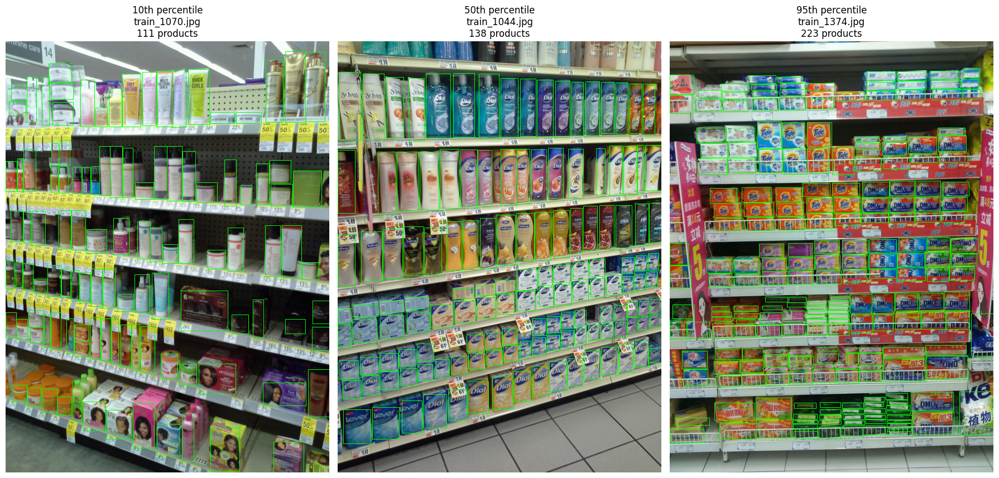

In [6]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import numpy as np

# Number of annotated products in each image
counts = df.groupby("image_name").size()

# Representative density levels
percentiles = [0.10, 0.50, 0.95]

selected_images = []

for q in percentiles:
    target = counts.quantile(q)
    image_name = (counts - target).abs().idxmin()
    selected_images.append((q, image_name))

fig, axes = plt.subplots(1, 3, figsize=(18, 9))

for ax, (q, image_name) in zip(axes, selected_images):

    image_path = ROOT / "images" / image_name

    with Image.open(image_path) as im:
        W, H = im.size
        im.thumbnail((850, 1100))
        image = im.convert("RGB")

    display_w, display_h = image.size

    sx = display_w / W
    sy = display_h / H

    annotations = df[
        df["image_name"] == image_name
    ]

    ax.imshow(image)

    for _, row in annotations.iterrows():

        x1 = np.clip(row["x1"], 0, W)
        y1 = np.clip(row["y1"], 0, H)
        x2 = np.clip(row["x2"], 0, W)
        y2 = np.clip(row["y2"], 0, H)

        if x2 <= x1 or y2 <= y1:
            continue

        rect = Rectangle(
            (x1 * sx, y1 * sy),
            (x2 - x1) * sx,
            (y2 - y1) * sy,
            linewidth=0.7,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(
        f"{int(q * 100)}th percentile\n"
        f"{image_name}\n"
        f"{len(annotations)} products"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

import numpy as np
import pandas as pd

# Use training annotations from the previous cells.
data = df.copy()

# Apply our agreed coordinate clipping.
data["x1"] = data["x1"].clip(lower=0)
data["y1"] = data["y1"].clip(lower=0)

data["x2"] = np.minimum(
    data["x2"], data["image_width"]
)
data["y2"] = np.minimum(
    data["y2"], data["image_height"]
)

# Original bounding-box dimensions.
data["box_w"] = data["x2"] - data["x1"]
data["box_h"] = data["y2"] - data["y1"]

assert (data["box_w"] > 0).all()
assert (data["box_h"] > 0).all()

print("ORIGINAL PRODUCT DIMENSIONS")
print("=" * 50)

print(
    data[["box_w", "box_h"]].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

# Simulate letterbox resizing for candidate sizes.
results = []

for imgsz in [640, 960, 1280]:

    # Preserve aspect ratio by scaling longest side.
    scale = np.minimum(
        imgsz / data["image_width"],
        imgsz / data["image_height"]
    )

    scaled_w = data["box_w"] * scale
    scaled_h = data["box_h"] * scale

    results.append({
        "Image size": imgsz,
        "Median width": scaled_w.median(),
        "Median height": scaled_h.median(),
        "Width < 4px (%)": 100 * (scaled_w < 4).mean(),
        "Width < 8px (%)": 100 * (scaled_w < 8).mean(),
        "Width < 16px (%)": 100 * (scaled_w < 16).mean(),
        "Height < 8px (%)": 100 * (scaled_h < 8).mean(),
        "Area < 256px² (%)":
            100 * ((scaled_w * scaled_h) < 256).mean()
    })

summary = pd.DataFrame(results)

print("\nPRODUCT SIZES AFTER RESIZING")
print("=" * 50)

display(summary.round(2))


ORIGINAL PRODUCT DIMENSIONS
            box_w       box_h
count  1208482.00  1208482.00
mean       120.79      190.11
std         72.59       96.28
min         17.00       21.00
10%         53.00       74.00
25%         74.00      113.00
50%        103.00      181.00
75%        146.00      253.00
90%        205.00      317.00
max       2226.00     2283.00

PRODUCT SIZES AFTER RESIZING


,Image size,Median width,Median height,Width < 4px (%),Width < 8px (%),Width < 16px (%),Height < 8px (%),Area < 256px² (%)
0,640,20.50,36.0,0.05,3.97,30.37,1.82,11.10
1,960,30.75,54.0,0.00,0.70,10.44,0.34,2.19
2,1280,41.00,72.0,0.00,0.05,3.97,0.02,0.51


In [8]:

from pathlib import Path
import pandas as pd
import numpy as np
import shutil
import yaml

ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

OUTPUT = Path("/kaggle/working/sku110k_pilot")

COLUMNS = [
    "image_name", "x1", "y1", "x2", "y2",
    "class", "image_width", "image_height"
]

SEED = 42
SPLIT_SIZES = {
    "train": 256,
    "val": 64
}

manifest_rows = []

for split, n_images in SPLIT_SIZES.items():

    df_split = pd.read_csv(
        ROOT / "annotations" / f"annotations_{split}.csv",
        header=None,
        names=COLUMNS
    )

    # Calculate products per image.
    counts = df_split.groupby("image_name").size()

    # Divide images into five density quintiles.
    density_bins = pd.qcut(
        counts.rank(method="first"),
        q=5,
        labels=False
    )

    # Sample approximately equally from each quintile.
    selected = []
    base, remainder = divmod(n_images, 5)

    for group_id in range(5):

        quota = base + int(group_id < remainder)

        candidates = counts.index[
            density_bins == group_id
        ]

        sampled = pd.Series(candidates).sample(
            n=quota,
            random_state=SEED + group_id +
                         (100 if split == "val" else 0)
        ).tolist()

        selected.extend(sampled)

        for name in sampled:
            manifest_rows.append({
                "split": split,
                "image_name": name,
                "product_count": int(counts[name]),
                "density_quintile": group_id
            })

    selected = sorted(selected)

    image_out = OUTPUT / "images" / split
    label_out = OUTPUT / "labels" / split

    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    selected_df = df_split[
        df_split["image_name"].isin(selected)
    ].copy()

    # Clip coordinates to valid image boundaries.
    selected_df["x1"] = selected_df["x1"].clip(lower=0)
    selected_df["y1"] = selected_df["y1"].clip(lower=0)

    selected_df["x2"] = np.minimum(
        selected_df["x2"],
        selected_df["image_width"]
    )

    selected_df["y2"] = np.minimum(
        selected_df["y2"],
        selected_df["image_height"]
    )

    # Reject boxes with non-positive visible area.
    selected_df = selected_df[
        (selected_df["x2"] > selected_df["x1"]) &
        (selected_df["y2"] > selected_df["y1"])
    ]

    total_boxes = 0

    for image_name, group in selected_df.groupby(
        "image_name"
    ):

        W = group["image_width"].to_numpy()
        H = group["image_height"].to_numpy()

        x1 = group["x1"].to_numpy()
        y1 = group["y1"].to_numpy()
        x2 = group["x2"].to_numpy()
        y2 = group["y2"].to_numpy()

        # Convert xyxy to normalized YOLO xywh.
        xc = ((x1 + x2) / 2) / W
        yc = ((y1 + y2) / 2) / H
        bw = (x2 - x1) / W
        bh = (y2 - y1) / H

        boxes = np.column_stack([xc, yc, bw, bh])

        assert np.isfinite(boxes).all()
        assert ((boxes >= 0) & (boxes <= 1)).all()
        assert (boxes[:, 2:] > 0).all()

        lines = [
            f"0 {x:.8f} {y:.8f} {w:.8f} {h:.8f}"
            for x, y, w, h in boxes
        ]

        label_path = label_out / (
            Path(image_name).stem + ".txt"
        )
        label_path.write_text("\n".join(lines) + "\n")

        shutil.copy2(
            ROOT / "images" / image_name,
            image_out / image_name
        )

        total_boxes += len(lines)

    print(
        f"{split}: {len(selected)} images, "
        f"{total_boxes:,} annotations"
    )

# Create dataset configuration file.
config = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {0: "object"}
}

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# Save exact sampling manifest.
manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(
    OUTPUT / "subset_manifest.csv",
    index=False
)

print("\nDataset prepared at:", OUTPUT)
print("Manifest entries:", len(manifest))
print("YAML:")
print((OUTPUT / "data.yaml").read_text())


train: 256 images, 37,604 annotations
val: 64 images, 10,362 annotations

Dataset prepared at: /kaggle/working/sku110k_pilot
Manifest entries: 320
YAML:
path: /kaggle/working/sku110k_pilot
train: images/train
val: images/val
nc: 1
names:
  0: object



train: 256 images, 256 labels, 37,604 valid boxes
val: 64 images, 64 labels, 10,362 valid boxes


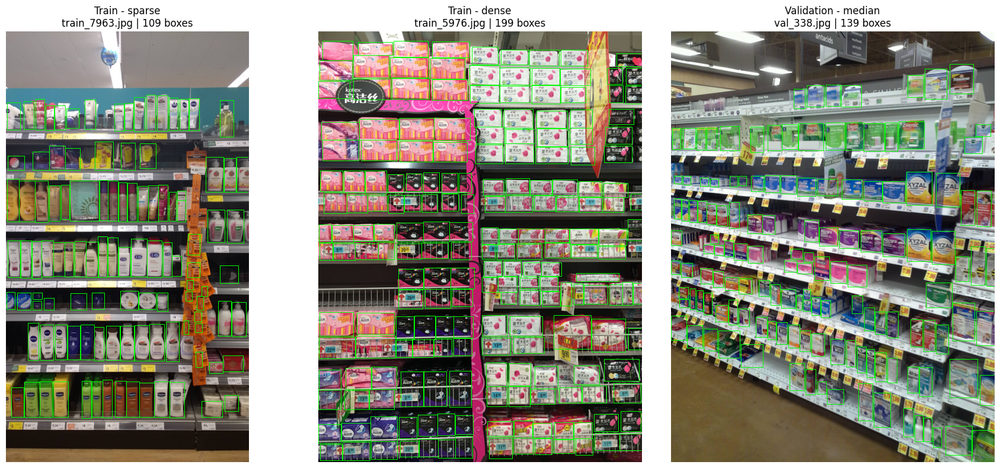

In [9]:

from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PILOT = Path("/kaggle/working/sku110k_pilot")

# ---------------------------------------
# 1. Check converted labels
# ---------------------------------------

for split in ["train", "val"]:

    image_dir = PILOT / "images" / split
    label_dir = PILOT / "labels" / split

    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    assert image_stems == label_stems, (
        f"Image/label mismatch in {split}"
    )

    total_boxes = 0

    for label_path in labels:

        boxes = np.loadtxt(
            label_path,
            ndmin=2
        )

        assert boxes.shape[1] == 5
        assert np.isfinite(boxes).all()
        assert (boxes[:, 0] == 0).all()

        xywh = boxes[:, 1:]

        assert (xywh[:, :2] >= 0).all()
        assert (xywh[:, :2] <= 1).all()
        assert (xywh[:, 2:] > 0).all()

        # Reconstruct normalized box corners.
        x1y1 = xywh[:, :2] - xywh[:, 2:] / 2
        x2y2 = xywh[:, :2] + xywh[:, 2:] / 2

        assert (x1y1 >= -1e-6).all()
        assert (x2y2 <= 1 + 1e-6).all()

        total_boxes += len(boxes)

    print(
        f"{split}: {len(images)} images, "
        f"{len(labels)} labels, "
        f"{total_boxes:,} valid boxes"
    )

# ---------------------------------------
# 2. Select representative images
# ---------------------------------------

manifest = pd.read_csv(
    PILOT / "subset_manifest.csv"
)

train_rows = manifest[
    manifest["split"] == "train"
].sort_values("product_count")

val_rows = manifest[
    manifest["split"] == "val"
].sort_values("product_count")

selected = [
    ("Train - sparse", train_rows.iloc[
        len(train_rows) // 10
    ]),
    ("Train - dense", train_rows.iloc[
        int(len(train_rows) * 0.9)
    ]),
    ("Validation - median", val_rows.iloc[
        len(val_rows) // 2
    ])
]

# ---------------------------------------
# 3. Visualize YOLO annotations
# ---------------------------------------

fig, axes = plt.subplots(
    1, 3, figsize=(18, 8)
)

for ax, (title, row) in zip(axes, selected):

    split = row["split"]
    image_name = row["image_name"]

    image_path = (
        PILOT / "images" / split / image_name
    )

    label_path = (
        PILOT / "labels" / split /
        f"{Path(image_name).stem}.txt"
    )

    with Image.open(image_path) as im:
        im.thumbnail((850, 1100))
        image = im.convert("RGB")

    W, H = image.size

    boxes = np.loadtxt(
        label_path,
        ndmin=2
    )

    ax.imshow(image)

    for cls, xc, yc, bw, bh in boxes:

        x1 = (xc - bw / 2) * W
        y1 = (yc - bh / 2) * H

        rect = Rectangle(
            (x1, y1),
            bw * W,
            bh * H,
            linewidth=0.7,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(
        f"{title}\n"
        f"{image_name} | {len(boxes)} boxes"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:
%pip install -q ultralytics

Note: you may need to restart the kernel to use updated packages.


In [11]:
import ultralytics
from ultralytics import YOLO
import torch

print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GiB"
)

model = YOLO("yolo11n.pt")

print("Model task:", model.task)
print("Pretrained weights loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.190
GPU: Tesla T4
GPU memory: 14.56 GiB
Model task: detect
Pretrained weights loaded successfully.


In [12]:

from ultralytics import YOLO
from pathlib import Path
import torch
import time

DATA_YAML = (
    "/kaggle/working/sku110k_pilot/data.yaml"
)

assert Path(DATA_YAML).exists()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(0)

model = YOLO("yolo11n.pt")

start = time.perf_counter()

results = model.train(
    data=DATA_YAML,
    epochs=1,
    imgsz=1280,
    batch=2,
    device=0,
    amp=True,
    workers=2,
    cache=False,
    mosaic=0.0,
    mixup=0.0,
    max_det=750,
    seed=42,
    deterministic=True,
    save=True,
    plots=True,
    project="/kaggle/working/sku110k_runs",
    name="pilot_yolo11n_1280",
    exist_ok=True,
    verbose=True
)

elapsed = time.perf_counter() - start

print("\n===== BENCHMARK SUMMARY =====")
print(f"Total time: {elapsed / 60:.2f} minutes")
print(
    "Peak GPU memory allocated:",
    round(
        torch.cuda.max_memory_allocated(0) / 1024**3,
        2
    ),
    "GiB"
)

RUN_DIR = Path(
    "/kaggle/working/sku110k_runs/"
    "pilot_yolo11n_1280"
)

print("\nArtifacts:")
for name in [
    "results.csv",
    "results.png",
    "args.yaml",
    "weights/best.pt",
    "weights/last.pt"
]:
    p = RUN_DIR / name
    print(name, "FOUND" if p.exists() else "NOT FOUND")


Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/sku110k_pilot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=750, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=pilot_yolo11n_1280, nbs=64, nms=None, opset=None, o

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


Optimizer stripped from /kaggle/working/sku110k_runs/pilot_yolo11n_1280/weights/best.pt, 5.6MB

Validating /kaggle/working/sku110k_runs/pilot_yolo11n_1280/weights/best.pt...
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.1s/it 17.4s0.2s
                   all         64      10362      0.189      0.188     0.0967     0.0349
Speed: 1.3ms preprocess, 216.4ms inference, 0.0ms loss, 30.9ms postprocess per image
Results saved to /kaggle/working/sku110k_runs/pilot_yolo11n_1280

===== BENCHMARK SUMMARY =====
Total time: 1.34 minutes
Peak GPU memory allocated: 1.51 GiB

Artifacts:
results.csv FOUND
results.png FOUND
args.yaml FOUND
weights/best.pt FOUND
weights/last.pt FOUND


In [13]:

from ultralytics import YOLO
from pathlib import Path
import torch
import time

DATA_YAML = "/kaggle/working/sku110k_pilot/data.yaml"

assert Path(DATA_YAML).exists()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(0)

model = YOLO("yolo11s.pt")

start = time.perf_counter()

results = model.train(
    data=DATA_YAML,
    epochs=1,
    imgsz=1280,
    batch=2,
    device=0,
    amp=True,
    workers=2,
    cache=False,
    mosaic=0.0,
    mixup=0.0,
    max_det=750,
    seed=42,
    deterministic=True,
    save=True,
    plots=True,
    project="/kaggle/working/sku110k_runs",
    name="pilot_yolo11s_1280",
    exist_ok=True,
    verbose=True
)

elapsed = time.perf_counter() - start

print("\n===== YOLO11s BENCHMARK =====")
print(f"Total runtime: {elapsed / 60:.2f} minutes")

print(
    "Peak PyTorch GPU allocation:",
    round(
        torch.cuda.max_memory_allocated(0) / 1024**3,
        2
    ),
    "GiB"
)

print(
    "GPU capacity:",
    round(
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3,
        2
    ),
    "GiB"
)


Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/sku110k_pilot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=750, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=pilot_yolo11s_1280, nbs=64, nms=None, opset=None, o

In [14]:

from pathlib import Path
import pandas as pd
import shutil
import torch
import time
from ultralytics import YOLO

ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

# --------------------------------
# 1. Storage audit
# --------------------------------

total_bytes = 0

for split in ["train", "val"]:

    csv_path = (
        ROOT / "annotations" /
        f"annotations_{split}.csv"
    )

    names = pd.read_csv(
        csv_path,
        header=None,
        usecols=[0]
    )[0].unique()

    split_bytes = sum(
        (ROOT / "images" / name).stat().st_size
        for name in names
    )

    total_bytes += split_bytes

    print(
        f"{split}: {len(names):,} images, "
        f"{split_bytes / 1024**3:.2f} GiB"
    )

usage = shutil.disk_usage("/kaggle/working")

print("\nSTORAGE SUMMARY")
print(
    "Full train + val image size:",
    round(total_bytes / 1024**3, 2),
    "GiB"
)
print(
    "Available working disk:",
    round(usage.free / 1024**3, 2),
    "GiB"
)

# --------------------------------
# 2. YOLO11s batch-size benchmark
# --------------------------------

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(0)

model = YOLO("yolo11s.pt")

start = time.perf_counter()

results = model.train(
    data="/kaggle/working/sku110k_pilot/data.yaml",
    epochs=1,
    imgsz=1280,
    batch=8,
    device=0,
    amp=True,
    workers=2,
    cache=False,
    mosaic=0.0,
    mixup=0.0,
    max_det=750,
    seed=42,
    deterministic=True,
    save=True,
    plots=False,
    project="/kaggle/working/sku110k_runs",
    name="pilot_yolo11s_batch8",
    exist_ok=True
)

elapsed = time.perf_counter() - start

print("\n===== BATCH 8 RESULTS =====")
print(f"Total runtime: {elapsed:.1f} seconds")

print(
    "Peak allocated:",
    round(
        torch.cuda.max_memory_allocated(0) / 1024**3,
        2
    ),
    "GiB"
)

print(
    "Peak reserved:",
    round(
        torch.cuda.max_memory_reserved(0) / 1024**3,
        2
    ),
    "GiB"
)


train: 8,219 images, 8.42 GiB
val: 588 images, 0.61 GiB

STORAGE SUMMARY
Full train + val image size: 9.03 GiB
Available working disk: 19.03 GiB
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/sku110k_pilot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=75

In [15]:

from pathlib import Path
import pandas as pd
import numpy as np
import yaml

ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

OUTPUT = Path("/kaggle/working/sku110k_full")

COLUMNS = [
    "image_name", "x1", "y1", "x2", "y2",
    "class", "image_width", "image_height"
]

summary = {}
split_names = {}

for split in ["train", "val"]:

    df = pd.read_csv(
        ROOT / "annotations" / f"annotations_{split}.csv",
        header=None,
        names=COLUMNS
    )

    assert set(df["class"].unique()) == {"object"}

    names = sorted(df["image_name"].unique())
    split_names[split] = set(names)

    img_out = OUTPUT / "images" / split
    lbl_out = OUTPUT / "labels" / split

    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    # Clip bounding boxes to image boundaries
    df["x1"] = df["x1"].clip(lower=0)
    df["y1"] = df["y1"].clip(lower=0)

    df["x2"] = np.minimum(
        df["x2"], df["image_width"]
    )
    df["y2"] = np.minimum(
        df["y2"], df["image_height"]
    )

    valid = (
        (df["x2"] > df["x1"]) &
        (df["y2"] > df["y1"])
    )

    dropped = int((~valid).sum())
    df = df.loc[valid]

    total_boxes = 0

    for image_name, group in df.groupby(
        "image_name", sort=False
    ):

        W = group["image_width"].to_numpy()
        H = group["image_height"].to_numpy()

        x1 = group["x1"].to_numpy()
        y1 = group["y1"].to_numpy()
        x2 = group["x2"].to_numpy()
        y2 = group["y2"].to_numpy()

        xywh = np.column_stack([
            (x1 + x2) / (2 * W),
            (y1 + y2) / (2 * H),
            (x2 - x1) / W,
            (y2 - y1) / H
        ])

        assert np.isfinite(xywh).all()
        assert (xywh[:, 2:] > 0).all()

        coords1 = xywh[:, :2] - xywh[:, 2:] / 2
        coords2 = xywh[:, :2] + xywh[:, 2:] / 2

        assert (coords1 >= -1e-7).all()
        assert (coords2 <= 1 + 1e-7).all()

        yolo_labels = np.column_stack([
            np.zeros(len(xywh), dtype=int),
            xywh
        ])

        label_path = (
            lbl_out / f"{Path(image_name).stem}.txt"
        )

        np.savetxt(
            label_path,
            yolo_labels,
            fmt=["%d", "%.8f", "%.8f", "%.8f", "%.8f"]
        )

        total_boxes += len(group)

    # Create image symlinks without copying JPEG data
    for image_name in names:

        src = ROOT / "images" / image_name
        dst = img_out / image_name

        assert src.is_file(), f"Missing: {src}"

        if dst.is_symlink():
            assert dst.resolve() == src.resolve()
        elif dst.exists():
            raise RuntimeError(
                f"Unexpected existing file: {dst}"
            )
        else:
            dst.symlink_to(src)

    summary[split] = {
        "images": len(names),
        "boxes": total_boxes,
        "dropped_boxes": dropped,
        "label_files": len(list(lbl_out.glob("*.txt")))
    }

    print(f"\n{split.upper()}: {summary[split]}")

assert split_names["train"].isdisjoint(
    split_names["val"]
)

config = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {0: "object"}
}

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nFull dataset prepared:", OUTPUT)
print("YAML:")
print((OUTPUT / "data.yaml").read_text())

# Confirm symlink functionality
example = next((OUTPUT / "images/train").glob("*.jpg"))

print("Symlink:", example.is_symlink())
print("Target exists:", example.resolve().is_file())



TRAIN: {'images': 8219, 'boxes': 1208482, 'dropped_boxes': 0, 'label_files': 8219}

VAL: {'images': 588, 'boxes': 90968, 'dropped_boxes': 0, 'label_files': 588}

Full dataset prepared: /kaggle/working/sku110k_full
YAML:
path: /kaggle/working/sku110k_full
train: images/train
val: images/val
nc: 1
names:
  0: object

Symlink: True
Target exists: True


In [16]:

from pathlib import Path
from ultralytics.data.dataset import YOLODataset
from ultralytics.data.utils import check_det_dataset
import time

DATA_YAML = Path(
    "/kaggle/working/sku110k_full/data.yaml"
)

# Check Ultralytics dataset configuration.
data = check_det_dataset(
    str(DATA_YAML),
    autodownload=False
)

print("Dataset configuration:")
print("Train:", data["train"])
print("Val:", data["val"])
print("Classes:", data["names"])

expected = {
    "train": (8219, 1208482),
    "val": (588, 90968)
}

for split, (expected_images, expected_boxes) in expected.items():

    print(f"\n{'=' * 50}")
    print(f"SCANNING {split.upper()}")
    print(f"{'=' * 50}")

    start = time.perf_counter()

    dataset = YOLODataset(
        img_path=data[split],
        data=data,
        task="detect",
        imgsz=1280,
        batch_size=2,
        augment=False,
        cache=False,
        prefix=f"{split}: "
    )

    n_images = len(dataset)
    n_boxes = sum(
        len(label["bboxes"])
        for label in dataset.labels
    )

    elapsed = time.perf_counter() - start

    print("Images loaded:", n_images)
    print("Boxes loaded:", n_boxes)
    print(f"Loading time: {elapsed:.2f}s")

    print(
        "Image count matches:",
        n_images == expected_images
    )
    print(
        "Box count matches:",
        n_boxes == expected_boxes
    )

    if n_images != expected_images:
        print("WARNING: Some images were not loaded.")

    if n_boxes != expected_boxes:
        print("WARNING: Some annotations were removed.")

    del dataset

print("\nUltralytics dataset scan complete.")


Dataset configuration:
Train: /kaggle/working/sku110k_full/images/train
Val: /kaggle/working/sku110k_full/images/val
Classes: {0: 'object'}

SCANNING TRAIN
WARNING ⚠️ train: Slow image access detected (ping: 0.3±0.0 ms, read: 3.3±1.3 MB/s, size: 1209.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
train: Scanning /kaggle/working/sku110k_full/labels/train... 8216 images, 0 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 8219/8219 8.9it/s 15:250.1sss
train: /kaggle/working/sku110k_full/images/train/train_1025.jpg: corrupt JPEG restored and saved
train: /kaggle/working/sku110k_full/images/train/train_1046.jpg: corrupt JPEG restored and saved
train: /kaggle/working/sku110k_full/images/train/train_1051.jpg: corrupt JPEG restored and saved
train: /kaggle/working/sku110k_full/images/train/train_1097.jpg: corrupt JPEG restored and saved
train: /kaggle/working/sku110k_full/images/train/train_1107.jpg: corru

train_4222.jpg: RECOVERED | Dimensions: (2448, 3264) | Size: 2414.0 KB
train_882.jpg: RECOVERED | Dimensions: (2448, 3264) | Size: 2421.2 KB
train_924.jpg: RECOVERED | Dimensions: (2448, 3264) | Size: 2544.7 KB


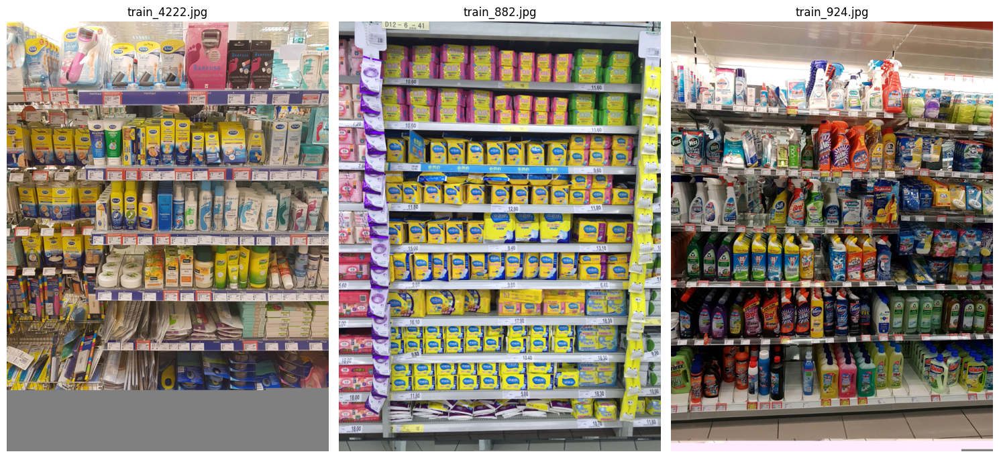

In [17]:

from pathlib import Path
from PIL import Image, ImageFile
import matplotlib.pyplot as plt

ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

REPAIR_DIR = Path("/kaggle/working/jpeg_repairs")
REPAIR_DIR.mkdir(parents=True, exist_ok=True)

affected = [
    "train_4222.jpg",
    "train_882.jpg",
    "train_924.jpg"
]

recovered = []

# Enable recovery only for this operation.
previous_setting = ImageFile.LOAD_TRUNCATED_IMAGES
ImageFile.LOAD_TRUNCATED_IMAGES = True

try:
    for name in affected:
        source = ROOT / "images" / name
        destination = REPAIR_DIR / name

        with Image.open(source) as im:
            original_size = im.size
            im.load()  # Force pixel decoding
            rgb = im.convert("RGB")

        rgb.save(
            destination,
            format="JPEG",
            quality=95,
            subsampling=0
        )

        # Verify the saved image with strict decoding.
        ImageFile.LOAD_TRUNCATED_IMAGES = False

        with Image.open(destination) as check:
            check.verify()

        with Image.open(destination) as check:
            check.load()
            assert check.size == original_size

        ImageFile.LOAD_TRUNCATED_IMAGES = True

        recovered.append(destination)

        print(
            f"{name}: RECOVERED | "
            f"Dimensions: {original_size} | "
            f"Size: {destination.stat().st_size / 1024:.1f} KB"
        )

finally:
    ImageFile.LOAD_TRUNCATED_IMAGES = previous_setting

# Display recovered images for visual inspection.
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

for ax, path in zip(axes, recovered):
    with Image.open(path) as im:
        im.thumbnail((650, 900))
        ax.imshow(im.convert("RGB"))

    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [18]:

from pathlib import Path
from PIL import Image, ImageFile

DATASET = Path("/kaggle/working/sku110k_full")
REPAIR_DIR = Path("/kaggle/working/jpeg_repairs")

affected = [
    "train_4222.jpg",
    "train_882.jpg",
    "train_924.jpg"
]

for name in affected:
    repaired = REPAIR_DIR / name
    target = DATASET / "images/train" / name

    assert repaired.is_file(), f"Missing repair: {name}"
    assert target.is_symlink(), f"Unexpected image path: {target}"

    # Strictly verify the repaired JPEG.
    previous = ImageFile.LOAD_TRUNCATED_IMAGES
    ImageFile.LOAD_TRUNCATED_IMAGES = False

    try:
        with Image.open(repaired) as im:
            im.verify()

        with Image.open(repaired) as im:
            im.load()
    finally:
        ImageFile.LOAD_TRUNCATED_IMAGES = previous

    # Replace the original symlink.
    target.unlink()
    target.symlink_to(repaired)

    assert target.resolve() == repaired.resolve()

    print(f"Updated: {name}")

# Remove outdated Ultralytics training cache.
cache = DATASET / "labels/train.cache"

if cache.exists():
    cache.unlink()
    print("Removed stale training cache.")

print("\nAll three repaired images are linked.")


Updated: train_4222.jpg
Updated: train_882.jpg
Updated: train_924.jpg
Removed stale training cache.

All three repaired images are linked.


In [19]:

from ultralytics import YOLO
from pathlib import Path
import torch
import time
import pandas as pd

DATA_YAML = "/kaggle/working/sku110k_full/data.yaml"

RUN_NAME = "sku110k_yolo11s_1280_full_v1"
PROJECT = "/kaggle/working/sku110k_runs"

assert Path(DATA_YAML).exists()
assert torch.cuda.is_available()

model = YOLO("yolo11s.pt")

torch.cuda.empty_cache()

start = time.perf_counter()

results = model.train(
    data=DATA_YAML,
    epochs=10,
    imgsz=1280,
    batch=2,
    device=0,
    amp=True,
    workers=2,
    cache=False,

    # Augmentation
    mosaic=0.0,
    mixup=0.0,

    # Evaluation
    val=True,
    max_det=750,
    plots=True,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Checkpointing
    save=True,
    save_period=1,

    # Output
    project=PROJECT,
    name=RUN_NAME,
    exist_ok=False,
    verbose=True
)

elapsed = time.perf_counter() - start

RUN_DIR = Path(model.trainer.save_dir)

print("\n===== TRAINING COMPLETED =====")
print(f"Duration: {elapsed / 3600:.2f} hours")
print("Results directory:", RUN_DIR)

metrics_file = RUN_DIR / "results.csv"

if metrics_file.exists():
    metrics = pd.read_csv(metrics_file)
    metrics.columns = metrics.columns.str.strip()
    display(metrics.tail(10))

print("\nModel checkpoints:")
for p in sorted((RUN_DIR / "weights").glob("*.pt")):
    print(p.name, round(p.stat().st_size / 1024**2, 2), "MB")


Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/sku110k_full/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=750, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=sku110k_yolo11s_1280_full_v1, nbs=64, nms=None, op

Corrupt JPEG data: premature end of data segment


       1/10      3.46G      1.644      1.227      1.303        285       1280: 15% ━╸────────── 655/4110 5.3it/s 4:49<10:54

Corrupt JPEG data: 784 extraneous bytes before marker 0xd9


       1/10      3.46G      1.593      1.127      1.271        311       1280: 23% ━━╸───────── 952/4110 3.4it/s 6:50<15:30

Corrupt JPEG data: 12658 extraneous bytes before marker 0xd2


... (581 outputs left out)

Corrupt JPEG data: 786 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 147/147 5.7it/s 25.6s
                   all        588      90968      0.907       0.87      0.934      0.592
Speed: 0.5ms preprocess, 19.3ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /kaggle/working/sku110k_runs/sku110k_yolo11s_1280_full_v1

===== TRAINING COMPLETED =====
Duration: 1.83 hours
Results directory: /kaggle/working/sku110k_runs/sku110k_yolo11s_1280_full_v1


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,1731.64,1.48490,0.90456,1.20372,0.86824,0.78932,0.86716,0.51624,1.38315,0.77209,1.13454,0.000667,0.000667,0.000667
1,2,2264.27,1.41434,0.77191,1.15528,0.87959,0.82214,0.89014,0.54332,1.34659,0.71296,1.11570,0.001201,0.001201,0.001201
2,3,2796.39,1.38865,0.73871,1.13909,0.88044,0.82696,0.89383,0.54808,1.34755,0.68179,1.10484,0.001604,0.001604,0.001604
3,4,3330.66,1.36939,0.70546,1.12745,0.89184,0.83326,0.90716,0.56183,1.32231,0.66764,1.09769,0.001406,0.001406,0.001406
4,5,3863.39,1.35381,0.68305,1.11739,0.89208,0.84227,0.91213,0.56789,1.31266,0.64828,1.09296,0.001208,0.001208,0.001208
5,6,4395.88,1.33927,0.66349,1.11179,0.89318,0.85256,0.91905,0.57315,1.30581,0.62708,1.08708,0.001010,0.001010,0.001010
6,7,4928.93,1.32899,0.64449,1.10112,0.90212,0.85874,0.92671,0.58214,1.29491,0.61148,1.08153,0.000812,0.000812,0.000812
7,8,5461.68,1.31856,0.62996,1.09433,0.90006,0.85817,0.92673,0.58133,1.29556,0.60514,1.08414,0.000614,0.000614,0.000614
8,9,5995.03,1.30995,0.61547,1.09022,0.90564,0.86765,0.93001,0.58778,1.28488,0.59157,1.07452,0.000416,0.000416,0.000416
9,10,6528.48,1.29825,0.59957,1.08531,0.90694,0.87005,0.93357,0.59153,1.27791,0.58128,1.07420,0.000218,0.000218,0.000218



Model checkpoints:
best.pt 18.35 MB
epoch0.pt 90.52 MB
epoch1.pt 90.52 MB
epoch2.pt 90.52 MB
epoch3.pt 90.52 MB
epoch4.pt 90.52 MB
epoch5.pt 90.52 MB
epoch6.pt 90.52 MB
epoch7.pt 90.52 MB
epoch8.pt 90.52 MB
epoch9.pt 90.52 MB
last.pt 18.35 MB


In [20]:

from pathlib import Path
import pandas as pd
import zipfile

RUN_DIR = Path(
    "/kaggle/working/sku110k_runs/"
    "sku110k_yolo11s_1280_full_v1"
)

metrics = pd.read_csv(RUN_DIR / "results.csv")
metrics.columns = metrics.columns.str.strip()

metric_name = "metrics/mAP50-95(B)"

best_row = metrics.loc[metrics[metric_name].idxmax()]

print("===== TRAINING SUMMARY =====")
print("Completed epochs:", len(metrics))
print("Best epoch by mAP50-95:", int(best_row["epoch"]))
print("Best recorded mAP50-95:", round(
    float(best_row[metric_name]), 4
))

print("\nFinal training metrics:")
display(metrics.tail(3))

print("\n===== CHECKPOINTS =====")
for name in ["best.pt", "last.pt"]:
    path = RUN_DIR / "weights" / name
    print(
        name,
        "EXISTS" if path.exists() else "MISSING",
        f"({path.stat().st_size / 1024**2:.2f} MB)"
        if path.exists() else ""
    )

# Package essential artifacts for download.
archive_path = Path(
    "/kaggle/working/sku110k_training_artifacts.zip"
)

files = [
    "weights/best.pt",
    "weights/last.pt",
    "results.csv",
    "results.png",
    "args.yaml",
    "confusion_matrix.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png"
]

with zipfile.ZipFile(
    archive_path, "w",
    compression=zipfile.ZIP_DEFLATED
) as zf:
    for name in files:
        path = RUN_DIR / name
        if path.exists():
            zf.write(path, arcname=name)

print("\nArchive created:", archive_path)
print(
    "Archive size:",
    round(archive_path.stat().st_size / 1024**2, 2),
    "MB"
)


===== TRAINING SUMMARY =====
Completed epochs: 10
Best epoch by mAP50-95: 10
Best recorded mAP50-95: 0.5915

Final training metrics:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
7,8,5461.68,1.31856,0.62996,1.09433,0.90006,0.85817,0.92673,0.58133,1.29556,0.60514,1.08414,0.000614,0.000614,0.000614
8,9,5995.03,1.30995,0.61547,1.09022,0.90564,0.86765,0.93001,0.58778,1.28488,0.59157,1.07452,0.000416,0.000416,0.000416
9,10,6528.48,1.29825,0.59957,1.08531,0.90694,0.87005,0.93357,0.59153,1.27791,0.58128,1.07420,0.000218,0.000218,0.000218



===== CHECKPOINTS =====
best.pt EXISTS (18.35 MB)
last.pt EXISTS (18.35 MB)

Archive created: /kaggle/working/sku110k_training_artifacts.zip
Archive size: 34.07 MB


Image: val_100.jpg
Ground truth products: 139
Predicted products: 144
Mean detection confidence: 0.68


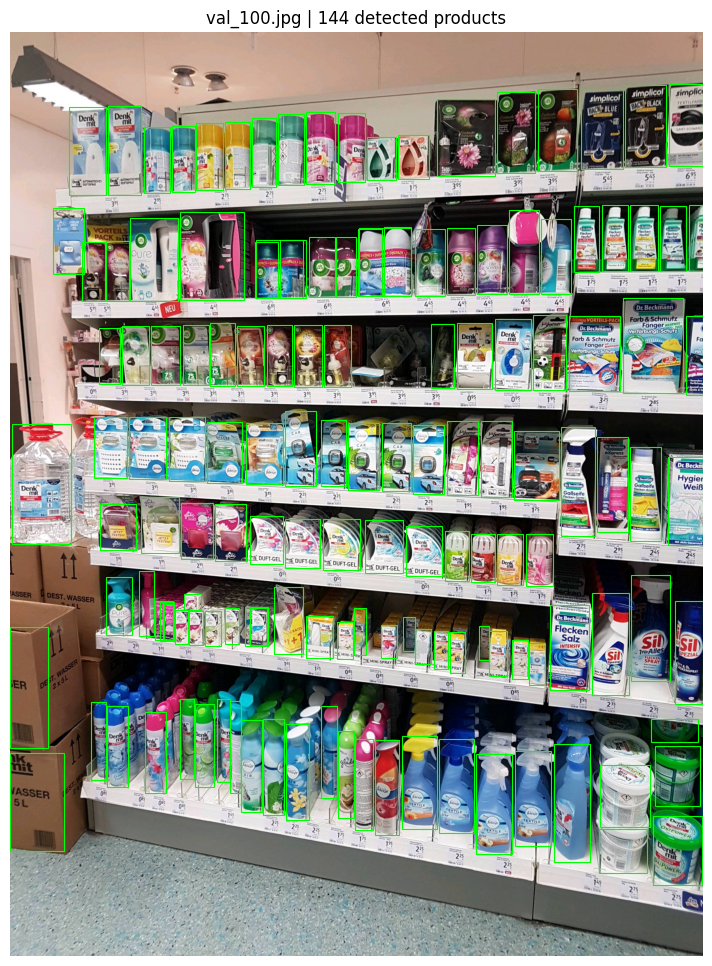

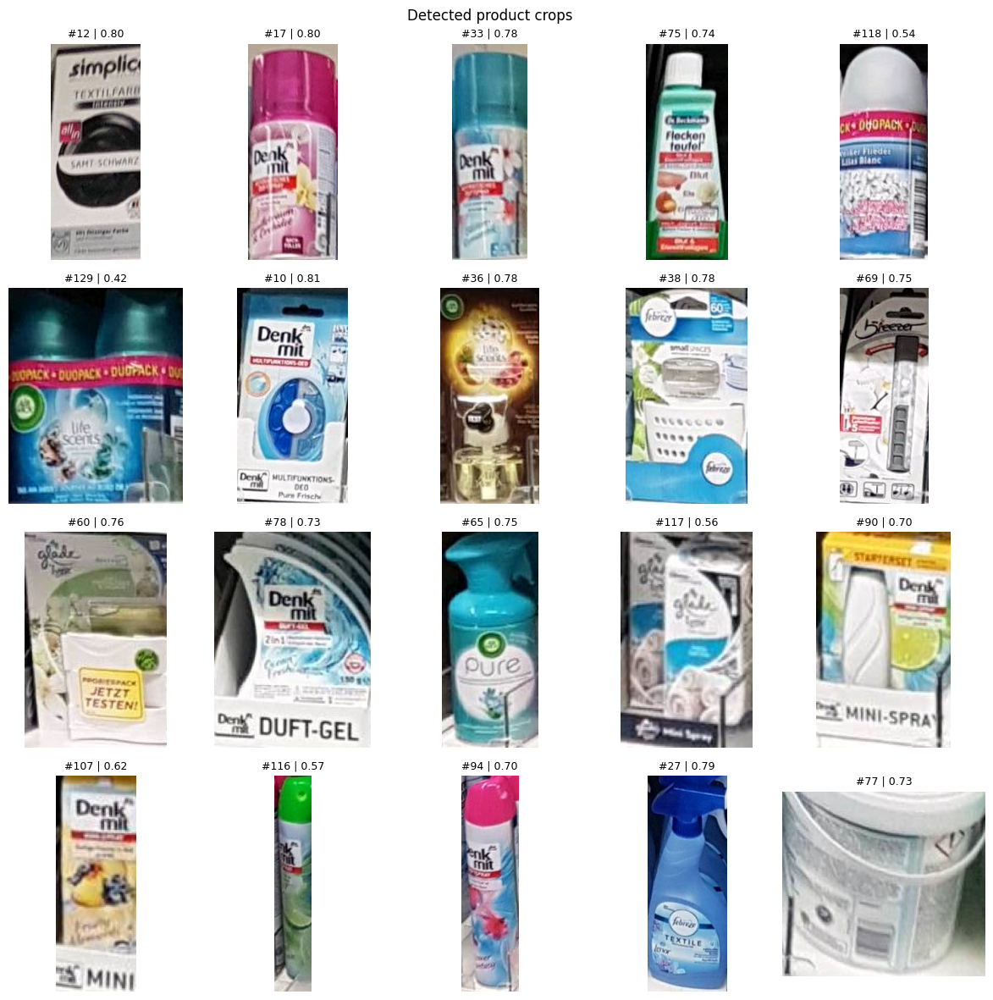

In [21]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

RUN_DIR = Path(
    "/kaggle/working/sku110k_runs/"
    "sku110k_yolo11s_1280_full_v1"
)

DATASET = Path("/kaggle/working/sku110k_full")

model = YOLO(str(RUN_DIR / "weights/best.pt"))

# Select a validation image with typical product density.
labels = sorted((DATASET / "labels/val").glob("*.txt"))

counts = pd.Series({
    p.stem: len(p.read_text().splitlines())
    for p in labels
})

selected_name = (counts - counts.median()).abs().idxmin()
image_path = DATASET / "images/val" / f"{selected_name}.jpg"

image = Image.open(image_path).convert("RGB")

# Run inference.
result = model.predict(
    source=str(image_path),
    imgsz=1280,
    conf=0.25,
    iou=0.7,
    max_det=750,
    device=0,
    verbose=False
)[0]

boxes = result.boxes.xyxy.cpu().numpy()
scores = result.boxes.conf.cpu().numpy()

print("Image:", image_path.name)
print("Ground truth products:", int(counts[selected_name]))
print("Predicted products:", len(boxes))
print("Mean detection confidence:",
      round(float(scores.mean()), 3) if len(scores) else "N/A")

# Visualize detections on the original image.
fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(image)

for x1, y1, x2, y2 in boxes:
    ax.add_patch(Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        edgecolor="lime",
        facecolor="none",
        linewidth=0.8
    ))

ax.set_title(
    f"{image_path.name} | {len(boxes)} detected products"
)
ax.axis("off")
plt.show()

# Extract representative product crops.
if len(boxes):
    ordered = np.lexsort((
        (boxes[:, 0] + boxes[:, 2]) / 2,
        (boxes[:, 1] + boxes[:, 3]) / 2
    ))

    chosen = ordered[
        np.linspace(
            0, len(ordered) - 1,
            min(20, len(ordered)),
            dtype=int
        )
    ]

    fig, axes = plt.subplots(4, 5, figsize=(12, 12))

    for ax in axes.flat:
        ax.axis("off")

    for ax, idx in zip(axes.flat, chosen):
        x1, y1, x2, y2 = boxes[idx].astype(int)

        crop = image.crop((x1, y1, x2, y2))

        ax.imshow(crop)
        ax.set_title(
            f"#{idx} | {scores[idx]:.2f}",
            fontsize=9
        )

    plt.suptitle("Detected product crops")
    plt.tight_layout()
    plt.show()


In [23]:
%pip install -q open_clip_torch

Note: you may need to restart the kernel to use updated packages.


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Crops: 144
Embedding shape: (144, 512)
Similarity matrix: (144, 144)


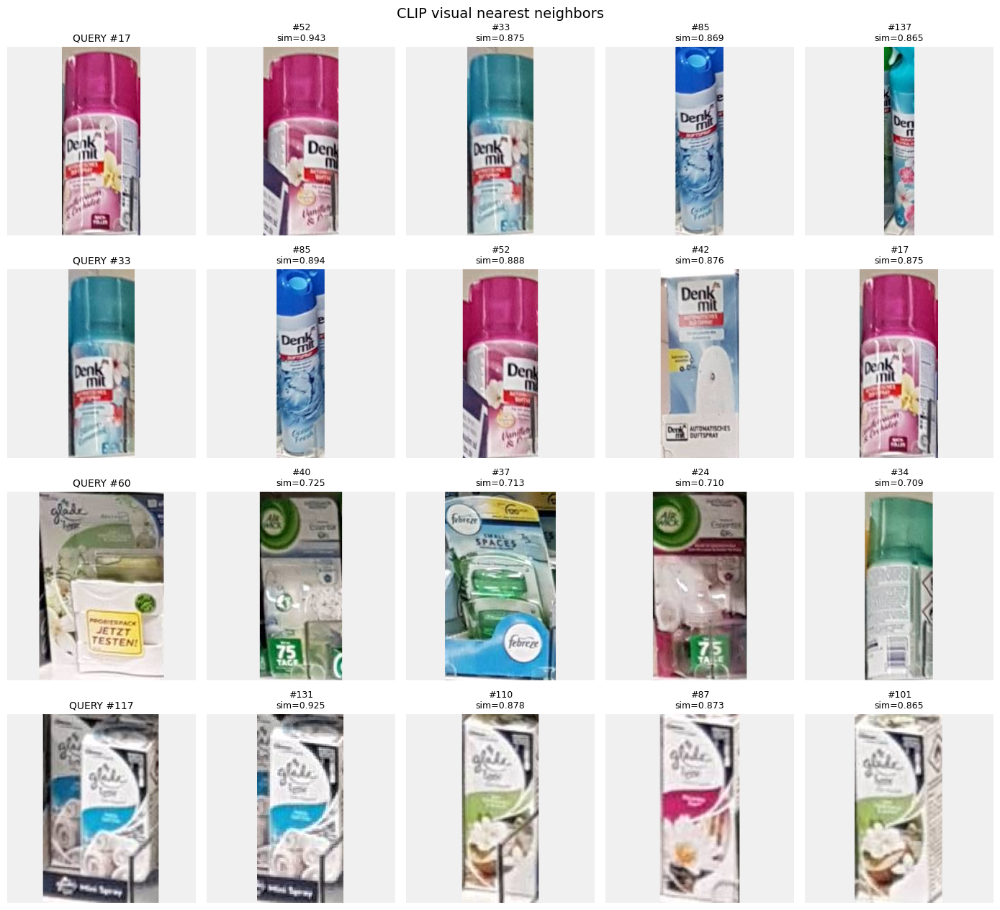


SELECTED PAIR SIMILARITIES
#17 vs #33: 0.8755
#17 vs #94: 0.8637
#10 vs #78: 0.8083
#60 vs #117: 0.6880
#17 vs #75: 0.8032


In [24]:

import open_clip
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

# Load pretrained CLIP visual encoder
clip_model, _, preprocess = (
    open_clip.create_model_and_transforms(
        "ViT-B-32",
        pretrained="openai",
        device=device
    )
)

clip_model.eval()

def pad_to_square(crop):
    """Preserve product aspect ratio."""
    w, h = crop.size
    size = max(w, h)

    canvas = Image.new(
        "RGB", (size, size), (240, 240, 240)
    )

    canvas.paste(
        crop,
        ((size - w) // 2, (size - h) // 2)
    )

    return canvas

# Extract all detected product crops.
crops = []
W, H = image.size

for x1, y1, x2, y2 in boxes:
    x1 = max(0, int(np.floor(x1)))
    y1 = max(0, int(np.floor(y1)))
    x2 = min(W, int(np.ceil(x2)))
    y2 = min(H, int(np.ceil(y2)))

    crop = image.crop((x1, y1, x2, y2))
    crops.append(pad_to_square(crop))

# Compute normalized CLIP embeddings in batches.
features = []

with torch.inference_mode():
    for start in range(0, len(crops), 16):
        batch = torch.stack([
            preprocess(c)
            for c in crops[start:start + 16]
        ]).to(device)

        embeddings = clip_model.encode_image(batch)
        embeddings = F.normalize(
            embeddings.float(), dim=-1
        )

        features.append(embeddings.cpu())

features = torch.cat(features).numpy()

# All-pairs cosine similarity matrix
similarity = features @ features.T

print("Crops:", len(crops))
print("Embedding shape:", features.shape)
print("Similarity matrix:", similarity.shape)

# Inspect nearest neighbors for known examples.
anchors = [17, 33, 60, 117]
k = 4

fig, axes = plt.subplots(
    len(anchors), k + 1,
    figsize=(14, 13)
)

for row, anchor in enumerate(anchors):
    ranked = np.argsort(
        -similarity[anchor]
    )
    ranked = ranked[ranked != anchor][:k]

    indices = [anchor] + list(ranked)

    for col, idx in enumerate(indices):
        ax = axes[row, col]
        ax.imshow(crops[idx])
        ax.axis("off")

        if col == 0:
            ax.set_title(
                f"QUERY #{anchor}",
                fontsize=10
            )
        else:
            ax.set_title(
                f"#{idx}\n"
                f"sim={similarity[anchor, idx]:.3f}",
                fontsize=9
            )

plt.suptitle(
    "CLIP visual nearest neighbors",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Compare a few illustrative pairs.
pairs = [
    (17, 33),
    (17, 94),
    (10, 78),
    (60, 117),
    (17, 75)
]

print("\nSELECTED PAIR SIMILARITIES")

for a, b in pairs:
    print(
        f"#{a} vs #{b}: "
        f"{similarity[a, b]:.4f}"
    )


In [25]:

import shutil
import subprocess
import tempfile
from pathlib import Path
from PIL import ImageOps, ImageEnhance

print("Tesseract installed:", shutil.which("tesseract"))

test_indices = [17, 33, 10, 78, 60, 117, 75, 40]

def prepare_for_ocr(img):
    img = img.convert("RGB")
    w, h = img.size

    # Enlarge small packaging text while preserving aspect ratio
    scale = max(1, 700 / max(w, h))

    img = img.resize(
        (int(w * scale), int(h * scale)),
        Image.Resampling.LANCZOS
    )

    gray = ImageOps.grayscale(img)
    gray = ImageEnhance.Contrast(gray).enhance(1.6)

    return gray

def recognize_text(img):
    with tempfile.TemporaryDirectory() as tmp:
        image_path = Path(tmp) / "crop.png"
        prepare_for_ocr(img).save(image_path)

        result = subprocess.run(
            [
                "tesseract",
                str(image_path),
                "stdout",
                "--psm", "11",
                "-l", "eng"
            ],
            capture_output=True,
            text=True
        )

        if result.returncode != 0:
            return f"ERROR: {result.stderr.strip()}"

        return " ".join(result.stdout.split())

if shutil.which("tesseract") is None:
    print("Tesseract executable unavailable.")
    print("OCR test not run.")
else:
    for idx in test_indices:
        text = recognize_text(crops[idx])

        print(f"\n{'=' * 45}")
        print(f"PRODUCT #{idx}")
        print(f"{'=' * 45}")
        print(text[:500] if text else "[No text detected]")


Tesseract installed: /usr/bin/tesseract

PRODUCT #17
mu. a 4 —_ | 4 we ree a

PRODUCT #33
zi ——— oA

PRODUCT #10
= re a ee MUL TUNRTIONS.” her (ee ron tech o

PRODUCT #78
berth Pie adh | heii: § DUFT-GEL

PRODUCT #60
— ola >. & — aoe, 8 JETZY TES TEN! | = ees

PRODUCT #117
«* ted, —. ~~

PRODUCT #75
fleckon toufol Pee, Nt 6.2 mse

PRODUCT #40
ky


# restoring notebook

In [2]:
%pip install -q ultralytics open_clip_torch

Note: you may need to restart the kernel to use updated packages.


In [6]:

from pathlib import Path

INPUT = Path("/kaggle/input")
WORKING = Path("/kaggle/working")

print("===== INPUT DIRECTORIES =====")

if INPUT.exists():
    for path in sorted(INPUT.iterdir()):
        print(path)
else:
    print("/kaggle/input does not exist!")

print("\n===== ALL ZIP FILES =====")
for path in INPUT.rglob("*.zip"):
    print(path)

print("\n===== ALL CHECKPOINT FILES =====")
for path in INPUT.rglob("*.pt"):
    print(path)

print("\n===== WORKING DIRECTORY =====")
for path in sorted(WORKING.iterdir()):
    print(path)


===== INPUT DIRECTORIES =====
/kaggle/input/datasets

===== ALL ZIP FILES =====

===== ALL CHECKPOINT FILES =====
/kaggle/input/datasets/jaybaradd/tnsqai-sku110k-yolo11s-training-artifacts/weights/best.pt
/kaggle/input/datasets/jaybaradd/tnsqai-sku110k-yolo11s-training-artifacts/weights/last.pt

===== WORKING DIRECTORY =====
/kaggle/working/.virtual_documents


In [7]:
from pathlib import Path
from ultralytics import YOLO
import torch

BEST_PT = Path(
    "/kaggle/input/datasets/jaybaradd/"
    "tnsqai-sku110k-yolo11s-training-artifacts/weights/best.pt"
)

assert BEST_PT.exists(), f"Checkpoint not found: {BEST_PT}"

model = YOLO(str(BEST_PT))

print("Model loaded successfully")
print("Checkpoint:", BEST_PT)
print("CUDA available:", torch.cuda.is_available())
print("Classes:", model.names)

Model loaded successfully
Checkpoint: /kaggle/input/datasets/jaybaradd/tnsqai-sku110k-yolo11s-training-artifacts/weights/best.pt
CUDA available: True
Classes: {0: 'object'}


Candidates: [PosixPath('/kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/images/val_100.jpg')]
Image: /kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/images/val_100.jpg
Detected products: 144
Mean confidence: 0.68


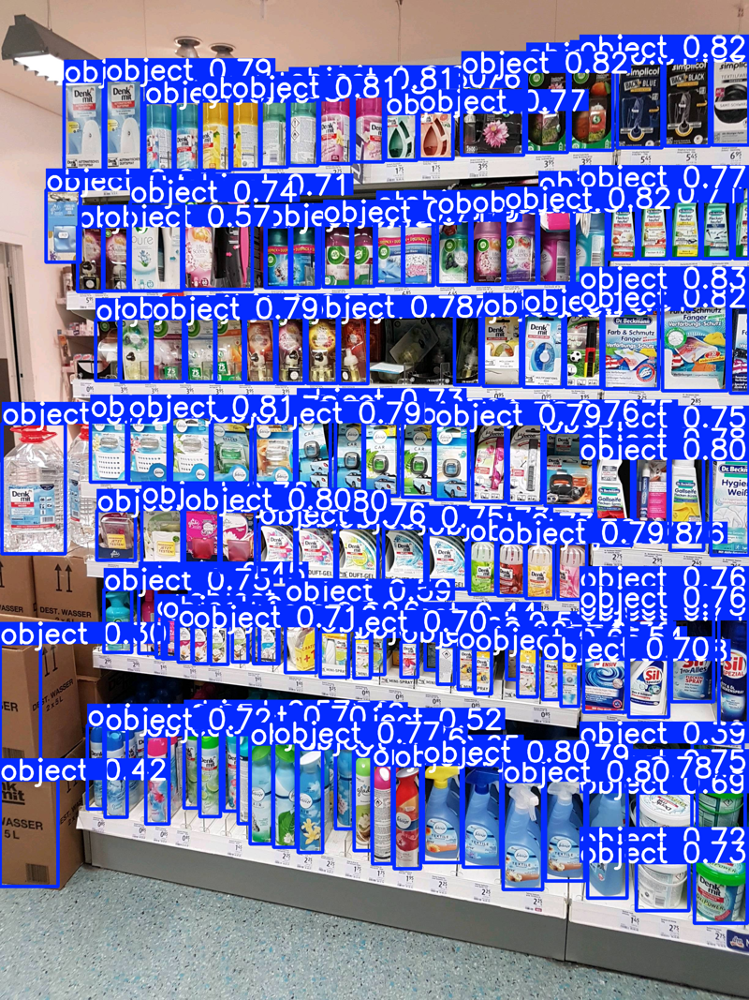

In [8]:
from pathlib import Path
from PIL import Image
from IPython.display import display

# Find the original SKU-110K image
candidates = list(Path("/kaggle/input").rglob("val_100.jpg"))
print("Candidates:", candidates)

assert candidates, "val_100.jpg not found in /kaggle/input"
image_path = candidates[0]

image = Image.open(image_path).convert("RGB")

result = model.predict(
    source=str(image_path),
    imgsz=1280,
    conf=0.25,
    iou=0.7,
    max_det=750,
    device=0,
    verbose=False
)[0]

boxes = result.boxes.xyxy.cpu().numpy()
scores = result.boxes.conf.cpu().numpy()

print("Image:", image_path)
print("Detected products:", len(boxes))
print("Mean confidence:", round(float(scores.mean()), 3) if len(scores) else None)

annotated = Image.fromarray(result.plot()[..., ::-1])
annotated.thumbnail((800, 1100))
display(annotated)

In [9]:

import open_clip
import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image
from pathlib import Path

device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model, _, preprocess = (
    open_clip.create_model_and_transforms(
        "ViT-B-32",
        pretrained="openai",
        device=device
    )
)
clip_model.eval()

def pad_to_square(crop):
    w, h = crop.size
    size = max(w, h)
    canvas = Image.new(
        "RGB", (size, size), (240, 240, 240)
    )
    canvas.paste(
        crop,
        ((size - w) // 2, (size - h) // 2)
    )
    return canvas

# Use the original image and current YOLO detections.
image = Image.open(image_path).convert("RGB")
W, H = image.size
crops = []

for x1, y1, x2, y2 in boxes:
    x1 = max(0, int(np.floor(x1)))
    y1 = max(0, int(np.floor(y1)))
    x2 = min(W, int(np.ceil(x2)))
    y2 = min(H, int(np.ceil(y2)))

    assert x2 > x1 and y2 > y1
    crops.append(
        pad_to_square(image.crop((x1, y1, x2, y2)))
    )

features = []

with torch.inference_mode():
    for start in range(0, len(crops), 16):
        batch = torch.stack([
            preprocess(c)
            for c in crops[start:start + 16]
        ]).to(device)

        embeddings = clip_model.encode_image(batch)
        embeddings = F.normalize(
            embeddings.float(), dim=-1
        )
        features.append(embeddings.cpu())

features = torch.cat(features).numpy()
similarity = features @ features.T

np.save(
    "/kaggle/working/clip_embeddings_val100.npy",
    features
)

print("Product crops:", len(crops))
print("Embeddings:", features.shape)
print("Similarity matrix:", similarity.shape)
print("CLIP feature extraction complete.")


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Product crops: 144
Embeddings: (144, 512)
Similarity matrix: (144, 144)
CLIP feature extraction complete.


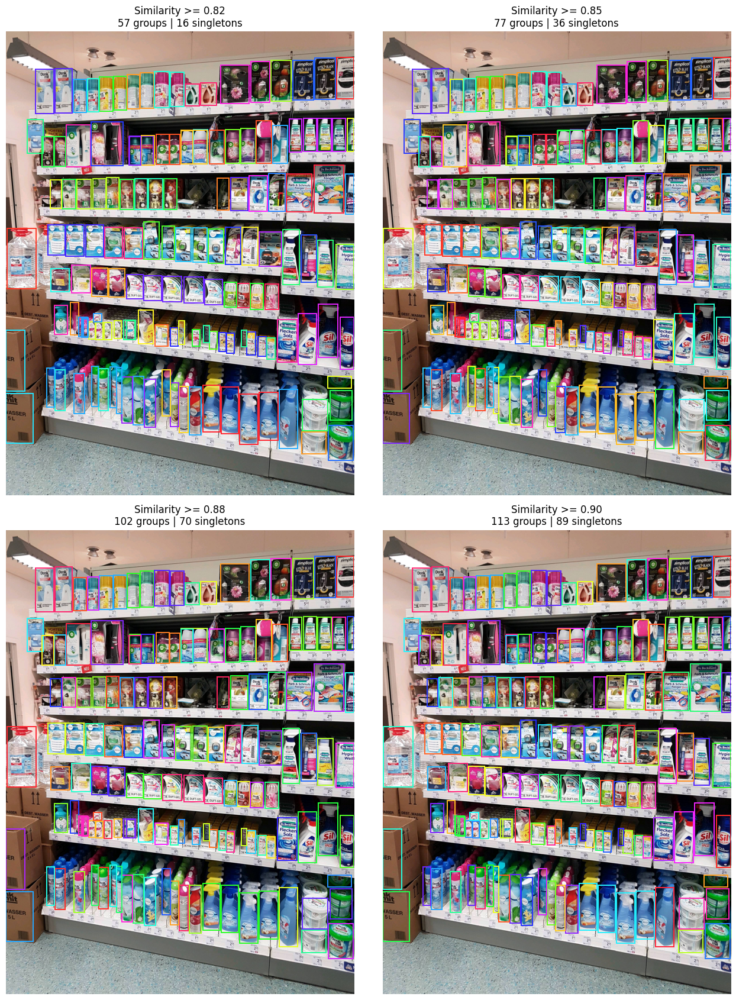

CLUSTERING COMPARISON


,Similarity threshold,Groups,Singleton groups,Multi-product groups,Largest group
0,0.82,57,16,41,11
1,0.85,77,36,41,5
2,0.88,102,70,32,4
3,0.90,113,89,24,4


In [10]:

from sklearn.cluster import AgglomerativeClustering
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

thresholds = [0.82, 0.85, 0.88, 0.90]

distance = np.maximum(
    0.0, 1.0 - np.clip(similarity, -1, 1)
)
np.fill_diagonal(distance, 0.0)

def cluster_products(similarity_cutoff):
    clustering = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=1 - similarity_cutoff,
        metric="precomputed",
        linkage="complete"
    )
    raw_labels = clustering.fit_predict(distance)

    # Deterministic group IDs ordered by product position.
    centers_x = (boxes[:, 0] + boxes[:, 2]) / 2
    centers_y = (boxes[:, 1] + boxes[:, 3]) / 2
    order = np.lexsort((centers_x, centers_y))

    mapping = {}
    for idx in order:
        old_id = int(raw_labels[idx])
        if old_id not in mapping:
            mapping[old_id] = len(mapping)

    return np.array([mapping[int(x)] for x in raw_labels])

def group_color(group_id):
    hue = (group_id * 0.61803398875) % 1.0
    return mcolors.hsv_to_rgb((hue, 0.85, 1.0))

fig, axes = plt.subplots(2, 2, figsize=(13, 17))
summary = []

for ax, threshold in zip(axes.flat, thresholds):
    labels = cluster_products(threshold)

    unique, counts = np.unique(
        labels, return_counts=True
    )

    n_groups = len(unique)
    singletons = int(np.sum(counts == 1))
    largest = int(counts.max())

    summary.append({
        "Similarity threshold": threshold,
        "Groups": n_groups,
        "Singleton groups": singletons,
        "Multi-product groups": n_groups - singletons,
        "Largest group": largest
    })

    ax.imshow(image)

    for i, (x1, y1, x2, y2) in enumerate(boxes):
        color = group_color(int(labels[i]))

        ax.add_patch(Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1.4,
            edgecolor=color,
            facecolor="none"
        ))

    ax.set_title(
        f"Similarity >= {threshold:.2f}\n"
        f"{n_groups} groups | "
        f"{singletons} singletons",
        fontsize=12
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame(summary)

print("CLUSTERING COMPARISON")
display(summary_df)


LARGEST GROUPS AT 0.82


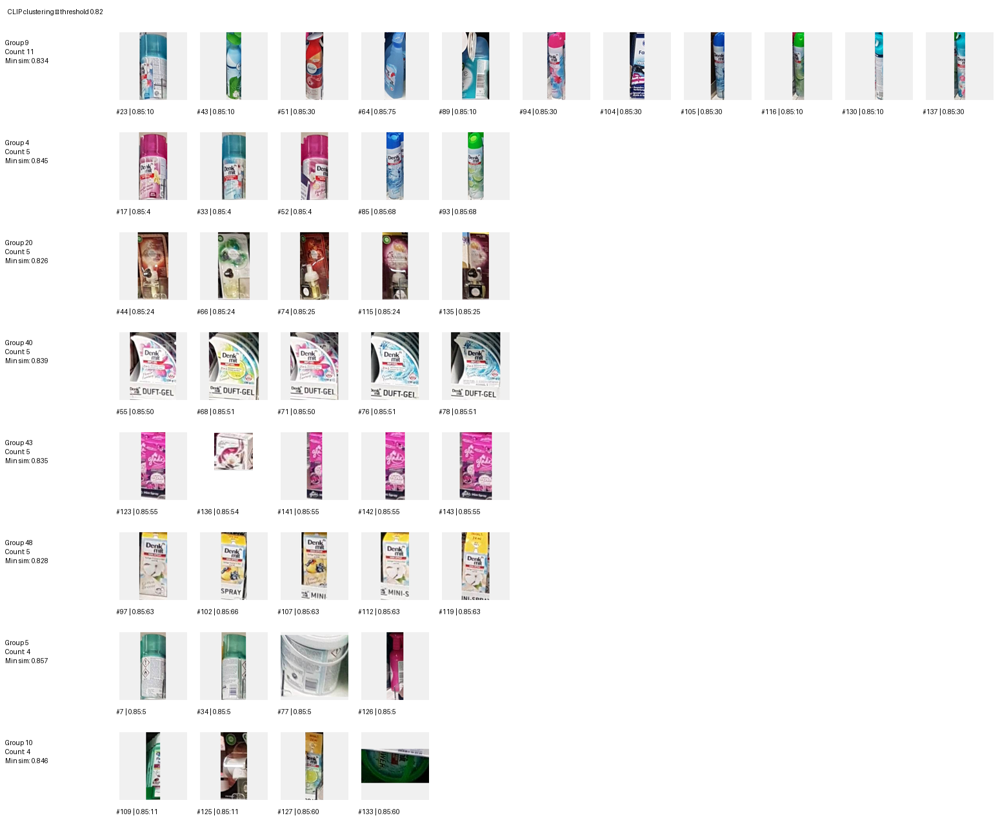


LARGEST GROUPS AT 0.85


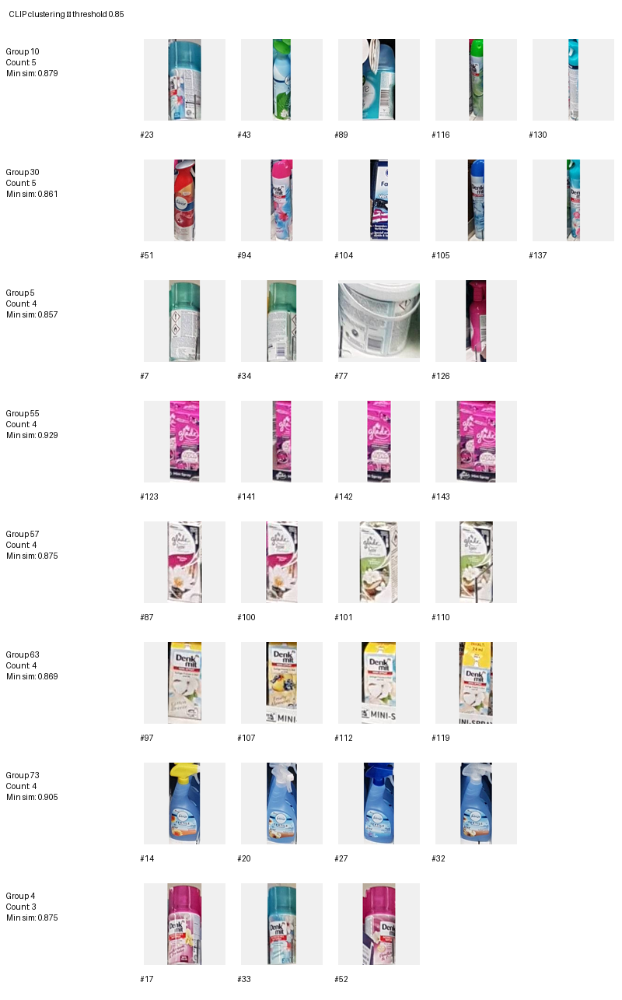

In [11]:

import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

labels_82 = cluster_products(0.82)
labels_85 = cluster_products(0.85)

def create_cluster_contact_sheet(
    labels,
    title,
    compare_labels=None,
    top_k=8
):
    unique, counts = np.unique(
        labels, return_counts=True
    )

    # Largest multi-product groups first.
    ranked = sorted(
        zip(unique, counts),
        key=lambda x: -x[1]
    )

    ranked = [
        (gid, n)
        for gid, n in ranked
        if n >= 2
    ][:top_k]

    cell_w = 125
    cell_h = 155
    label_w = 175

    max_members = max(n for _, n in ranked)

    canvas = Image.new(
        "RGB",
        (
            label_w + max_members * cell_w,
            45 + len(ranked) * cell_h
        ),
        "white"
    )

    draw = ImageDraw.Draw(canvas)
    draw.text((12, 12), title, fill="black")

    for row, (gid, n) in enumerate(ranked):

        members = np.where(labels == gid)[0]

        y = 45 + row * cell_h

        # Minimum intra-group similarity
        group_sims = similarity[
            np.ix_(members, members)
        ]

        if len(members) > 1:
            upper = group_sims[
                np.triu_indices(len(members), k=1)
            ]
            min_sim = float(upper.min())
        else:
            min_sim = 1.0

        draw.text(
            (8, y + 15),
            f"Group {gid}\n"
            f"Count: {n}\n"
            f"Min sim: {min_sim:.3f}",
            fill="black"
        )

        for col, idx in enumerate(members):

            crop = crops[idx].copy()
            crop.thumbnail((105, 112))

            x = label_w + col * cell_w

            canvas.paste(
                crop,
                (
                    x + (cell_w - crop.width) // 2,
                    y + 5
                )
            )

            caption = f"#{idx}"

            if compare_labels is not None:
                caption += f" | 0.85:{compare_labels[idx]}"

            draw.text(
                (x + 5, y + 122),
                caption,
                fill="black"
            )

    return canvas


print("LARGEST GROUPS AT 0.82")

sheet_82 = create_cluster_contact_sheet(
    labels_82,
    "CLIP clustering — threshold 0.82",
    compare_labels=labels_85,
    top_k=8
)

display(sheet_82)

print("\nLARGEST GROUPS AT 0.85")

sheet_85 = create_cluster_contact_sheet(
    labels_85,
    "CLIP clustering — threshold 0.85",
    top_k=8
)

display(sheet_85)


# trying DINOv2 for grouping

In [12]:
%pip install -q timm

Note: you may need to restart the kernel to use updated packages.


In [13]:

import timm
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Reuse existing 'crops' and CLIP 'similarity'
# from our previous Kaggle cells.

assert len(crops) == 144
clip_similarity = similarity.copy()

device = "cuda:0" if torch.cuda.is_available() else "cpu"

# Load DINOv2 ViT-S/14
dino_model = timm.create_model(
    "vit_small_patch14_dinov2.lvd142m",
    pretrained=True,
    num_classes=0
).to(device).eval()

# Use model-specific preprocessing
data_config = timm.data.resolve_model_data_config(
    dino_model
)

dino_transform = timm.data.create_transform(
    **data_config,
    is_training=False
)

# Extract embeddings
dino_features = []

with torch.inference_mode():
    for start in range(0, len(crops), 4):

        batch = torch.stack([
            dino_transform(c)
            for c in crops[start:start + 4]
        ]).to(device)

        if device.startswith("cuda"):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = dino_model(batch)
        else:
            outputs = dino_model(batch)

        outputs = F.normalize(
            outputs.float(),
            dim=-1
        )

        dino_features.append(outputs.cpu())

dino_features = torch.cat(
    dino_features
).numpy()

dino_similarity = dino_features @ dino_features.T

np.save(
    "/kaggle/working/dinov2_embeddings_val100.npy",
    dino_features
)

print("DINOv2 embeddings:", dino_features.shape)
print("Similarity matrix:", dino_similarity.shape)

# Compare previously inspected pairs
pairs = [
    (17, 52),
    (17, 33),
    (17, 75),
    (60, 117),
    (117, 131)
]

print("\nPAIR COMPARISON")
print("Pair       CLIP       DINOv2")

for a, b in pairs:
    print(
        f"{a:3d}-{b:<3d}   "
        f"{clip_similarity[a,b]:.3f}      "
        f"{dino_similarity[a,b]:.3f}"
    )


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

DINOv2 embeddings: (144, 384)
Similarity matrix: (144, 144)

PAIR COMPARISON
Pair       CLIP       DINOv2
 17-52    0.943      0.848
 17-33    0.875      0.849
 17-75    0.803      0.482
 60-117   0.688      0.541
117-131   0.925      0.938


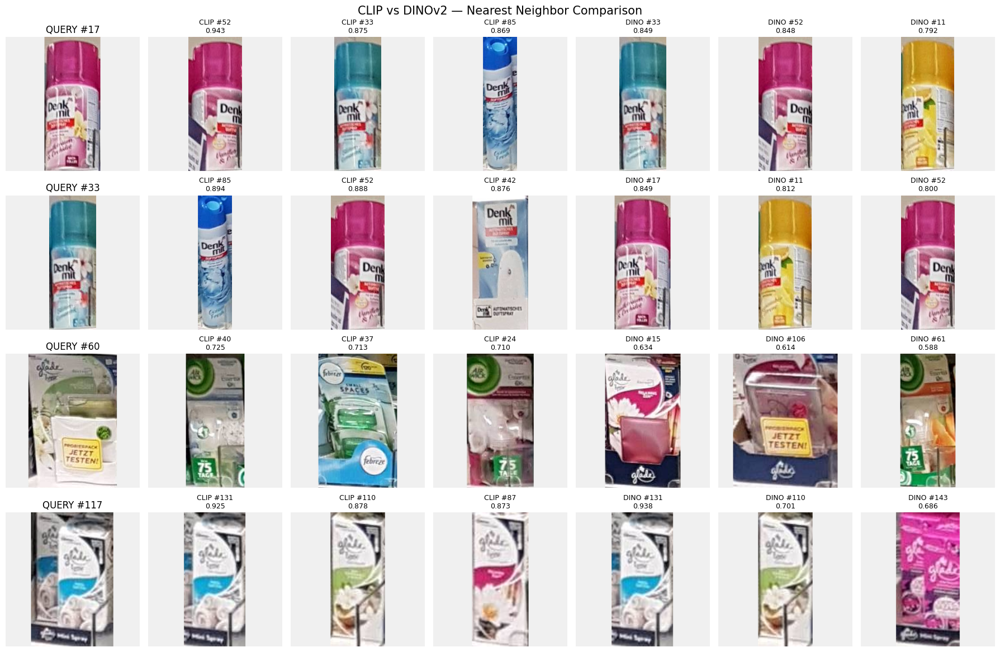

In [14]:

anchors = [17, 33, 60, 117]
k = 3

fig, axes = plt.subplots(
    len(anchors), 7,
    figsize=(18, 12)
)

for row, anchor in enumerate(anchors):

    clip_ranked = np.argsort(
        -clip_similarity[anchor]
    )
    clip_ranked = clip_ranked[
        clip_ranked != anchor
    ][:k]

    dino_ranked = np.argsort(
        -dino_similarity[anchor]
    )
    dino_ranked = dino_ranked[
        dino_ranked != anchor
    ][:k]

    # Query crop
    axes[row, 0].imshow(crops[anchor])
    axes[row, 0].set_title(f"QUERY #{anchor}")

    # CLIP nearest neighbors
    for col, idx in enumerate(clip_ranked, 1):
        axes[row, col].imshow(crops[idx])
        axes[row, col].set_title(
            f"CLIP #{idx}\n"
            f"{clip_similarity[anchor,idx]:.3f}",
            fontsize=9
        )

    # DINOv2 nearest neighbors
    for col, idx in enumerate(dino_ranked, 4):
        axes[row, col].imshow(crops[idx])
        axes[row, col].set_title(
            f"DINO #{idx}\n"
            f"{dino_similarity[anchor,idx]:.3f}",
            fontsize=9
        )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "CLIP vs DINOv2 — Nearest Neighbor Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [15]:

from sklearn.cluster import AgglomerativeClustering
import numpy as np

# CLIP baseline from our earlier experiment
clip_labels = cluster_products(0.85)

# DINOv2 — same number of groups
dino_distance = np.maximum(
    0.0,
    1.0 - np.clip(dino_similarity, -1, 1)
)
np.fill_diagonal(dino_distance, 0.0)

dino_clusterer = AgglomerativeClustering(
    n_clusters=77,
    metric="precomputed",
    linkage="complete"
)

dino_labels = dino_clusterer.fit_predict(
    dino_distance
)

print("CLIP groups:", len(np.unique(clip_labels)))
print("DINOv2 groups:", len(np.unique(dino_labels)))

# Compare group assignments for previously
# problematic CLIP clusters.
problem_groups = [5, 10, 30]

for group_id in problem_groups:
    members = np.where(
        clip_labels == group_id
    )[0]

    print(f"\nCLIP group {group_id}")
    print("Product IDs:", members.tolist())
    print(
        "DINOv2 group IDs:",
        dino_labels[members].tolist()
    )


CLIP groups: 77
DINOv2 groups: 77

CLIP group 5
Product IDs: [7, 34, 77, 126]
DINOv2 group IDs: [56, 56, 8, 43]

CLIP group 10
Product IDs: [23, 43, 89, 116, 130]
DINOv2 group IDs: [49, 20, 46, 9, 11]

CLIP group 30
Product IDs: [51, 94, 104, 105, 137]
DINOv2 group IDs: [63, 16, 6, 16, 9]


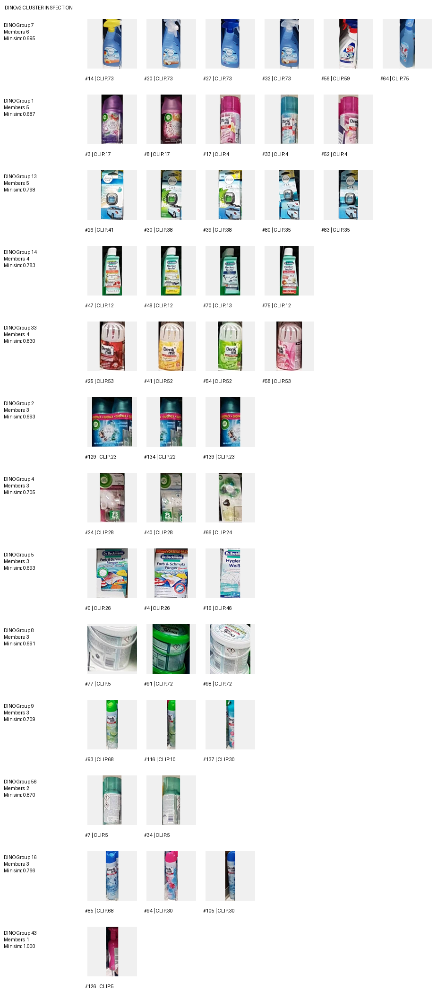

Total DINOv2 groups: 77
Singletons: 37
Largest group: 6


In [16]:

from PIL import Image, ImageDraw
from IPython.display import display
import numpy as np

# DINOv2 clustering results already available:
# dino_labels, dino_similarity, crops, clip_labels

unique, counts = np.unique(
    dino_labels, return_counts=True
)

ranked = sorted(
    zip(unique, counts),
    key=lambda item: -item[1]
)

# Largest multi-product clusters
selected_groups = [
    int(gid)
    for gid, count in ranked
    if count >= 2
][:10]

# Include groups relevant to our previous errors
for gid in [56, 16, 8, 43]:
    if gid not in selected_groups:
        selected_groups.append(gid)

cell_w = 125
row_h = 160
label_w = 175

max_members = max(
    int(np.sum(dino_labels == gid))
    for gid in selected_groups
)

canvas = Image.new(
    "RGB",
    (
        label_w + max_members * cell_w,
        35 + len(selected_groups) * row_h
    ),
    "white"
)

draw = ImageDraw.Draw(canvas)
draw.text((10, 10), "DINOv2 CLUSTER INSPECTION", fill="black")

for row, gid in enumerate(selected_groups):

    members = np.where(dino_labels == gid)[0]
    y = 35 + row * row_h

    sim_matrix = dino_similarity[
        np.ix_(members, members)
    ]

    if len(members) > 1:
        min_sim = sim_matrix[
            np.triu_indices(len(members), k=1)
        ].min()
    else:
        min_sim = 1.0

    draw.text(
        (8, y + 12),
        f"DINO Group {gid}\n"
        f"Members: {len(members)}\n"
        f"Min sim: {min_sim:.3f}",
        fill="black"
    )

    for col, idx in enumerate(members):
        crop = crops[idx].copy()
        crop.thumbnail((105, 115))

        x = label_w + col * cell_w

        canvas.paste(
            crop,
            (
                x + (cell_w - crop.width) // 2,
                y + 5
            )
        )

        draw.text(
            (x + 5, y + 125),
            f"#{idx} | CLIP:{clip_labels[idx]}",
            fill="black"
        )

display(canvas)

print("Total DINOv2 groups:", len(unique))
print("Singletons:", int(np.sum(counts == 1)))
print("Largest group:", int(counts.max()))


In [17]:

from sklearn.cluster import AgglomerativeClustering
import numpy as np
import pandas as pd

thresholds = [0.68, 0.70, 0.72, 0.75]

distance = np.maximum(
    0.0, 1.0 - np.clip(dino_similarity, -1, 1)
)
np.fill_diagonal(distance, 0.0)

def cluster_dino(threshold):
    clustering = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=1.0 - threshold,
        metric="precomputed",
        linkage="complete"
    )
    return clustering.fit_predict(distance)

rows = []

for threshold in thresholds:
    labels = cluster_dino(threshold)
    unique, counts = np.unique(
        labels, return_counts=True
    )

    rows.append({
        "Threshold": threshold,
        "Groups": len(unique),
        "Singletons": int((counts == 1).sum()),
        "Largest group": int(counts.max()),
        "Products grouped": int(counts[counts > 1].sum())
    })

display(pd.DataFrame(rows))

# Check known good and problematic groups.
reference = {
    "Denkmit sprays": [17, 33, 52],
    "Blue sprays + unrelated products": [14, 20, 27, 32, 56, 64],
    "Denkmit containers": [25, 41, 54, 58],
    "Mixed aerosols": [3, 8, 17, 33, 52]
}

for name, ids in reference.items():
    print(f"\n{name}")
    print("Products:", ids)

    for threshold in thresholds:
        labels = cluster_dino(threshold)

        groups = [int(labels[i]) for i in ids]

        print(
            f"  {threshold:.2f}: "
            f"{len(set(groups))} distinct groups"
        )


,Threshold,Groups,Singletons,Largest group,Products grouped
0,0.68,78,39,6,105
1,0.70,84,45,5,99
2,0.72,91,55,5,89
3,0.75,92,57,5,87



Denkmit sprays
Products: [17, 33, 52]
  0.68: 1 distinct groups
  0.70: 1 distinct groups
  0.72: 1 distinct groups
  0.75: 1 distinct groups

Blue sprays + unrelated products
Products: [14, 20, 27, 32, 56, 64]
  0.68: 1 distinct groups
  0.70: 2 distinct groups
  0.72: 2 distinct groups
  0.75: 2 distinct groups

Denkmit containers
Products: [25, 41, 54, 58]
  0.68: 1 distinct groups
  0.70: 1 distinct groups
  0.72: 1 distinct groups
  0.75: 1 distinct groups

Mixed aerosols
Products: [3, 8, 17, 33, 52]
  0.68: 1 distinct groups
  0.70: 2 distinct groups
  0.72: 2 distinct groups
  0.75: 2 distinct groups


In [18]:

import numpy as np
from sklearn.cluster import AgglomerativeClustering

def assign_appearance_groups(
    embeddings: np.ndarray,
    boxes: np.ndarray,
    threshold: float = 0.70
) -> np.ndarray:

    embeddings = np.asarray(embeddings, dtype=np.float32)
    boxes = np.asarray(boxes, dtype=np.float32)

    n = len(embeddings)

    assert len(boxes) == n

    if n == 0:
        return np.empty(0, dtype=int)

    if n == 1:
        return np.array([0], dtype=int)

    # L2 normalization
    norms = np.linalg.norm(
        embeddings, axis=1, keepdims=True
    )
    embeddings = embeddings / np.maximum(norms, 1e-12)

    # Pairwise cosine distance
    similarity = embeddings @ embeddings.T

    distance = 1.0 - np.clip(similarity, -1, 1)
    distance = np.maximum(distance, 0)
    np.fill_diagonal(distance, 0)

    clustering = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=1.0 - threshold,
        metric="precomputed",
        linkage="complete"
    )

    raw_labels = clustering.fit_predict(distance)

    # Deterministic IDs in top-to-bottom,
    # left-to-right image order.
    center_x = (boxes[:, 0] + boxes[:, 2]) / 2
    center_y = (boxes[:, 1] + boxes[:, 3]) / 2

    order = np.lexsort((center_x, center_y))

    mapping = {}

    for idx in order:
        cluster = int(raw_labels[idx])
        if cluster not in mapping:
            mapping[cluster] = len(mapping)

    return np.array(
        [mapping[int(g)] for g in raw_labels],
        dtype=int
    )


In [19]:
group_ids = assign_appearance_groups(
    dino_features,
    boxes,
    threshold=0.70
)

unique, counts = np.unique(
    group_ids, return_counts=True
)

print("Products:", len(group_ids))
print("Groups:", len(unique))
print("Singletons:", int((counts == 1).sum()))
print("Largest group:", int(counts.max()))

Products: 144
Groups: 84
Singletons: 45
Largest group: 5


In [20]:

from PIL import Image, ImageDraw
import numpy as np
import torch
import torch.nn.functional as F
import colorsys

def predict_shelf(image, threshold=0.70):
    image = image.convert("RGB")
    W, H = image.size

    # 1. Detect products with fine-tuned YOLO
    result = model.predict(
        source=image,
        imgsz=1280,
        conf=0.25,
        iou=0.7,
        max_det=750,
        device=0,
        verbose=False
    )[0]

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()

    # Handle empty images
    if len(boxes) == 0:
        return image.copy(), {
            "image_width": W,
            "image_height": H,
            "total_products": 0,
            "total_groups": 0,
            "detections": []
        }

    # 2. Extract aspect-ratio-preserving crops
    product_crops = []

    for x1, y1, x2, y2 in boxes:
        coords = (
            max(0, int(np.floor(x1))),
            max(0, int(np.floor(y1))),
            min(W, int(np.ceil(x2))),
            min(H, int(np.ceil(y2)))
        )

        product_crops.append(
            pad_to_square(image.crop(coords))
        )

    # 3. Extract DINOv2 embeddings
    embeddings = []

    with torch.inference_mode():
        for start in range(0, len(product_crops), 4):
            batch = torch.stack([
                dino_transform(c)
                for c in product_crops[start:start + 4]
            ]).to(device)

            vectors = dino_model(batch)
            vectors = F.normalize(
                vectors.float(), dim=-1
            )

            embeddings.append(
                vectors.cpu().numpy()
            )

    embeddings = np.concatenate(embeddings)

    # 4. Cluster visually similar products
    group_ids = assign_appearance_groups(
        embeddings,
        boxes,
        threshold=threshold
    )

    # 5. Draw group-colored bounding boxes
    annotated = image.copy()
    draw = ImageDraw.Draw(annotated)

    detections = []

    for idx, (box, score, gid) in enumerate(
        zip(boxes, scores, group_ids)
    ):
        x1, y1, x2, y2 = box.tolist()
        gid = int(gid)

        rgb = colorsys.hsv_to_rgb(
            (gid * 0.61803398875) % 1.0,
            0.85,
            1.0
        )
        color = tuple(int(c * 255) for c in rgb)

        draw.rectangle(
            [x1, y1, x2, y2],
            outline=color,
            width=max(2, W // 1000)
        )

        detections.append({
            "product_id": idx,
            "bbox": [round(float(v), 2) for v in box],
            "confidence": round(float(score), 4),
            "group_id": gid
        })

    output = {
        "image_width": W,
        "image_height": H,
        "total_products": len(detections),
        "total_groups": len(set(group_ids.tolist())),
        "grouping_method": "dinov2_agglomerative",
        "similarity_threshold": threshold,
        "detections": detections
    }

    return annotated, output


In [22]:
from pathlib import Path

DATA_ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

assert DATA_ROOT.exists(), "SKU-110K dataset not found"

test_path = DATA_ROOT / "images/val_100.jpg"

assert test_path.exists(), "Test image not found"

print("Dataset found:", DATA_ROOT)
print("Test image:", test_path)

Dataset found: /kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed
Test image: /kaggle/input/datasets/mohamedessam3112002/sku-110k/SKU110K_fixed/images/val_100.jpg


Products: 144
Appearance groups: 84
End-to-end inference: 6.27s

First 3 detections:
[
  {
    "product_id": 0,
    "bbox": [
      2165.66,
      940.06,
      2376.73,
      1275.88
    ],
    "confidence": 0.826,
    "group_id": 23
  },
  {
    "product_id": 1,
    "bbox": [
      1508.07,
      237.72,
      1711.61,
      506.53
    ],
    "confidence": 0.8244,
    "group_id": 3
  },
  {
    "product_id": 2,
    "bbox": [
      2172.82,
      186.1,
      2318.01,
      476.4
    ],
    "confidence": 0.8172,
    "group_id": 1
  }
]


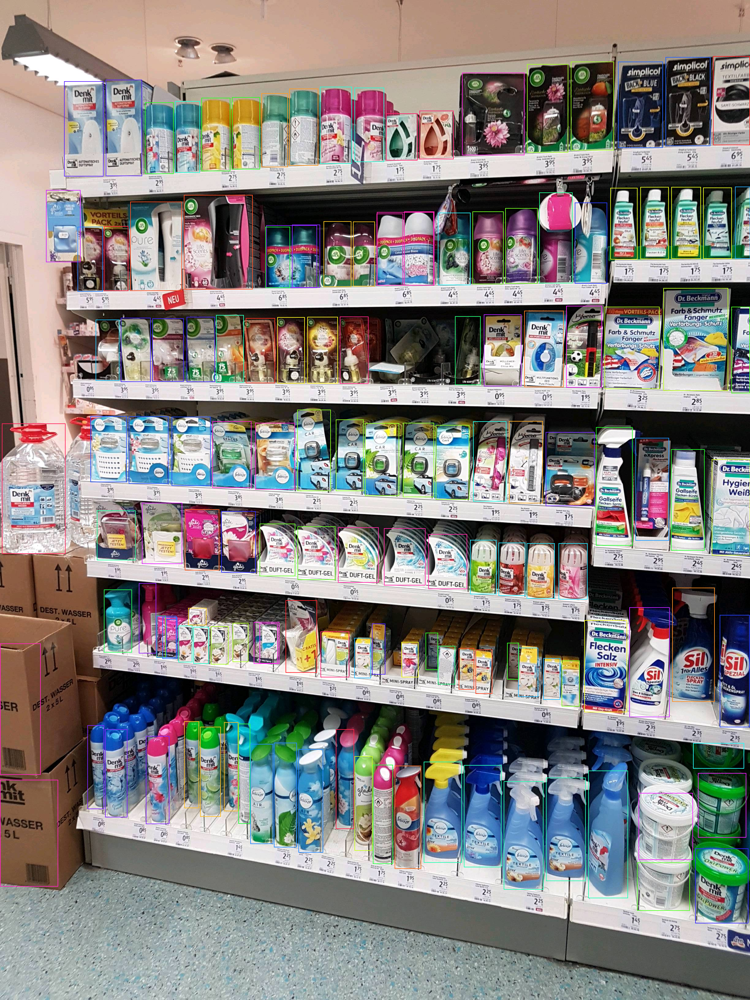

In [23]:

from PIL import Image
from IPython.display import display
from pathlib import Path
import json
import time

test_path = DATA_ROOT / "images/val_100.jpg"

start = time.perf_counter()

with Image.open(test_path) as im:
    annotated, prediction = predict_shelf(
        im, threshold=0.70
    )

elapsed = time.perf_counter() - start

print("Products:", prediction["total_products"])
print("Appearance groups:", prediction["total_groups"])
print(f"End-to-end inference: {elapsed:.2f}s")

print("\nFirst 3 detections:")
print(json.dumps(
    prediction["detections"][:3],
    indent=2
))

# Save outputs for later use in the README
output_dir = Path("/kaggle/working/example_outputs")
output_dir.mkdir(exist_ok=True)

annotated.save(
    output_dir / "val_100_grouped.jpg",
    quality=92
)

with open(output_dir / "val_100_results.json", "w") as f:
    json.dump(prediction, f, indent=2)

preview = annotated.copy()
preview.thumbnail((750, 1100))
display(preview)


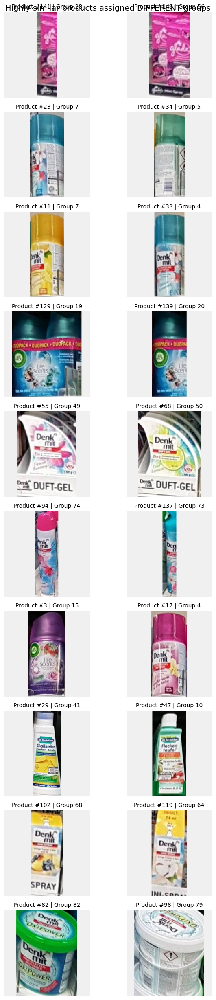

In [24]:

import numpy as np
import matplotlib.pyplot as plt

# Reuse existing embeddings, boxes, and crops.
labels = assign_appearance_groups(
    dino_features, boxes, threshold=0.70
)

sim = dino_features @ dino_features.T

candidates = []

for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        if labels[i] != labels[j]:
            candidates.append(
                (float(sim[i, j]), i, j)
            )

# Highest similarity pairs assigned different groups.
candidates.sort(reverse=True)

# Select diverse pairs to avoid repeating the same product.
selected = []
used = set()

for similarity_score, i, j in candidates:
    if i not in used and j not in used:
        selected.append((similarity_score, i, j))
        used.update([i, j])

    if len(selected) == 10:
        break

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(7, 2.5 * len(selected))
)

for row, (score, i, j) in enumerate(selected):
    for col, idx in enumerate([i, j]):
        ax = axes[row, col]
        ax.imshow(crops[idx])
        ax.axis("off")
        ax.set_title(
            f"Product #{idx} | Group {labels[idx]}",
            fontsize=10
        )

    axes[row, 0].set_ylabel(
        f"Similarity: {score:.3f}",
        fontsize=10
    )

plt.suptitle(
    "Highly similar products assigned DIFFERENT groups",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [25]:

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering

# Existing DINOv2 similarities
distance = np.maximum(
    0.0,
    1.0 - np.clip(dino_similarity, -1, 1)
)
np.fill_diagonal(distance, 0)

# Existing complete-linkage result
complete_labels = assign_appearance_groups(
    dino_features, boxes, threshold=0.70
)

n_groups = len(np.unique(complete_labels))

# Average-linkage comparison, matched group count
average_labels = AgglomerativeClustering(
    n_clusters=n_groups,
    metric="precomputed",
    linkage="average"
).fit_predict(distance)

# Selected visually related product pairs
positive_pairs = [
    (141, 136),
    (11, 33),
    (129, 139),
    (55, 68),
    (94, 137),
    (102, 119),
    (82, 98)
]

# Different-looking products that should stay separate
negative_pairs = [
    (3, 17),
    (29, 47),
    (14, 56)
]

def evaluate_pairs(pairs, expected_same):
    rows = []

    for a, b in pairs:
        complete_same = (
            complete_labels[a] == complete_labels[b]
        )
        average_same = (
            average_labels[a] == average_labels[b]
        )

        rows.append({
            "Pair": f"{a}-{b}",
            "DINO similarity": round(
                float(dino_similarity[a, b]), 3
            ),
            "Expected same": expected_same,
            "Complete same": complete_same,
            "Average same": average_same
        })

    return pd.DataFrame(rows)

print("RELATED PACKAGING PAIRS")
positive_results = evaluate_pairs(
    positive_pairs, True
)
display(positive_results)

print("\nDIFFERENT PACKAGING PAIRS")
negative_results = evaluate_pairs(
    negative_pairs, False
)
display(negative_results)

print("\nSUMMARY")

for name, labels in [
    ("Complete", complete_labels),
    ("Average", average_labels)
]:
    _, sizes = np.unique(labels, return_counts=True)

    print(
        name,
        "| Groups:", len(sizes),
        "| Singletons:", int((sizes == 1).sum()),
        "| Largest group:", int(sizes.max())
    )


RELATED PACKAGING PAIRS


,Pair,DINO similarity,Expected same,Complete same,Average same
0,141-136,0.645,True,False,False
1,11-33,0.812,True,False,False
2,129-139,0.810,True,False,True
3,55-68,0.806,True,False,True
4,94-137,0.796,True,False,True
5,102-119,0.768,True,False,False
6,82-98,0.760,True,False,False



DIFFERENT PACKAGING PAIRS


,Pair,DINO similarity,Expected same,Complete same,Average same
0,3-17,0.776,False,False,True
1,29-47,0.769,False,False,False
2,14-56,0.744,False,False,False



SUMMARY
Complete | Groups: 84 | Singletons: 45 | Largest group: 5
Average | Groups: 84 | Singletons: 51 | Largest group: 5


In [26]:

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering

positive_pairs = [
    (141, 136),
    (11, 33),
    (129, 139),
    (55, 68),
    (94, 137),
    (102, 119),
    (82, 98)
]

negative_pairs = [
    (3, 17),
    (29, 47),
    (14, 56)
]

distance = np.maximum(
    0.0,
    1.0 - np.clip(dino_similarity, -1, 1)
)
np.fill_diagonal(distance, 0)

thresholds = [
    0.68, 0.70, 0.72, 0.74,
    0.76, 0.78, 0.80, 0.82
]

results = []

for threshold in thresholds:

    labels = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=1.0 - threshold,
        metric="precomputed",
        linkage="average"
    ).fit_predict(distance)

    _, sizes = np.unique(labels, return_counts=True)

    true_positive = sum(
        labels[a] == labels[b]
        for a, b in positive_pairs
    )

    false_positive = sum(
        labels[a] == labels[b]
        for a, b in negative_pairs
    )

    results.append({
        "Threshold": threshold,
        "Groups": len(sizes),
        "Singletons": int((sizes == 1).sum()),
        "Related pairs grouped": true_positive,
        "Incorrect merges": false_positive,
        "Largest group": int(sizes.max())
    })

display(pd.DataFrame(results))


,Threshold,Groups,Singletons,Related pairs grouped,Incorrect merges,Largest group
0,0.68,71,38,5,3,6
1,0.70,75,42,4,3,6
2,0.72,82,49,4,1,5
3,0.74,90,56,2,0,5
4,0.76,94,62,1,0,5
5,0.78,99,70,0,0,5
6,0.80,104,78,0,0,5
7,0.82,108,85,0,0,5


In [30]:

import numpy as np
from sklearn.cluster import AgglomerativeClustering

GROUPING_THRESHOLD = 0.72

def assign_appearance_groups(
    embeddings: np.ndarray,
    boxes: np.ndarray,
    threshold: float = GROUPING_THRESHOLD
) -> np.ndarray:

    embeddings = np.asarray(
        embeddings, dtype=np.float32
    )
    boxes = np.asarray(boxes, dtype=np.float32)

    n = len(embeddings)

    if len(boxes) != n:
        raise ValueError("Embedding/box count mismatch")

    if n == 0:
        return np.empty(0, dtype=int)

    if n == 1:
        return np.array([0], dtype=int)

    # Normalize embeddings
    norms = np.linalg.norm(
        embeddings, axis=1, keepdims=True
    )
    embeddings = embeddings / np.maximum(norms, 1e-12)

    # Cosine distance matrix
    similarity = embeddings @ embeddings.T
    distance = np.maximum(
        0.0, 1.0 - np.clip(similarity, -1.0, 1.0)
    )
    np.fill_diagonal(distance, 0.0)

    # Average linkage allows packaging variation
    clusterer = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=1.0 - threshold,
        metric="precomputed",
        linkage="average"
    )

    raw_labels = clusterer.fit_predict(distance)

    # Deterministic group IDs: spatial order
    cx = (boxes[:, 0] + boxes[:, 2]) / 2
    cy = (boxes[:, 1] + boxes[:, 3]) / 2

    order = np.lexsort((cx, cy))
    mapping = {}

    for idx in order:
        label = int(raw_labels[idx])
        if label not in mapping:
            mapping[label] = len(mapping)

    return np.array(
        [mapping[int(label)] for label in raw_labels],
        dtype=int
    )


In [28]:
labels = assign_appearance_groups(
    dino_features,
    boxes,
    threshold=0.72
)

unique, counts = np.unique(
    labels, return_counts=True
)

print("Products:", len(labels))
print("Groups:", len(unique))
print("Singletons:", int((counts == 1).sum()))
print("Largest group:", int(counts.max()))

Products: 144
Groups: 82
Singletons: 49
Largest group: 5


===== INFERENCE RESULTS =====
Image: val_338.jpg
Products detected: 137
Appearance groups: 68
Singleton groups: 39
Largest group: 12
End-to-end inference time: 5.84s


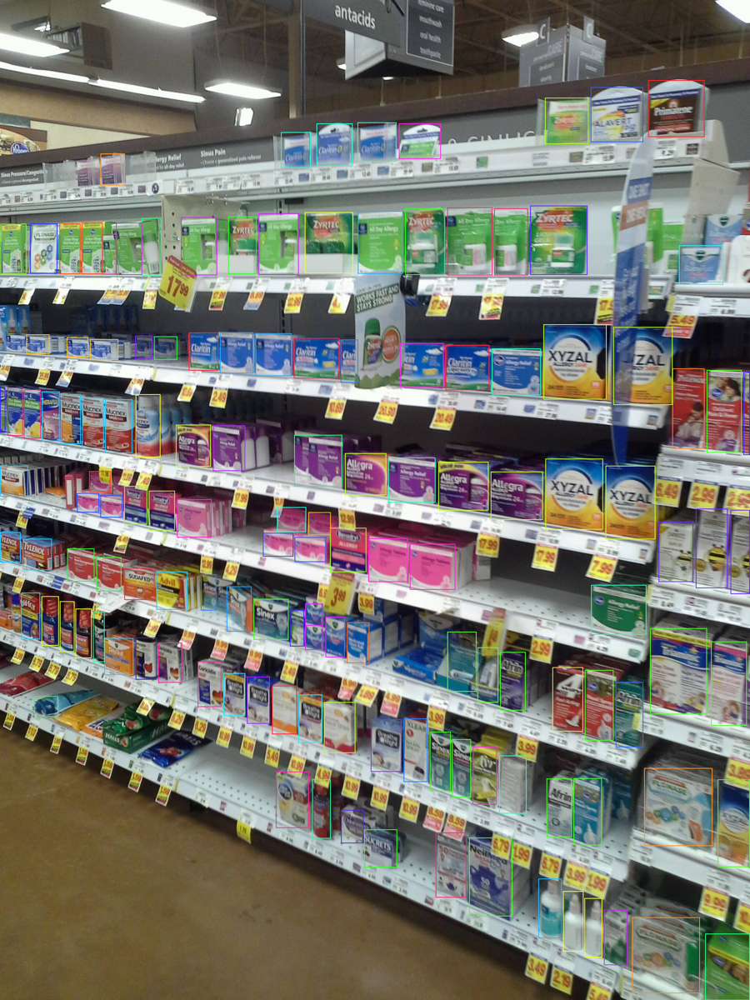

In [33]:

from pathlib import Path
from PIL import Image
from IPython.display import display
from collections import Counter
import time
import json

# Choose another SKU-110K validation image
IMAGE_NAME = "val_338.jpg"

DATA_ROOT = Path(
    "/kaggle/input/datasets/mohamedessam3112002/"
    "sku-110k/SKU110K_fixed"
)

test_path = DATA_ROOT / "images" / IMAGE_NAME

assert test_path.exists(), f"Image not found: {test_path}"

# Run our complete inference pipeline
start = time.perf_counter()

with Image.open(test_path) as im:
    annotated, prediction = predict_shelf(
        im,
        threshold=0.70
    )

elapsed = time.perf_counter() - start

# Group statistics
group_counts = Counter(
    d["group_id"]
    for d in prediction["detections"]
)

singletons = sum(
    1 for count in group_counts.values()
    if count == 1
)

print("===== INFERENCE RESULTS =====")
print("Image:", IMAGE_NAME)
print("Products detected:", prediction["total_products"])
print("Appearance groups:", prediction["total_groups"])
print("Singleton groups:", singletons)
print("Largest group:", max(group_counts.values(), default=0))
print(f"End-to-end inference time: {elapsed:.2f}s")

# Save results
output_dir = Path("/kaggle/working/example_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

annotated.save(
    output_dir / f"{test_path.stem}_grouped.jpg",
    quality=92
)

with open(
    output_dir / f"{test_path.stem}_results.json", "w"
) as f:
    json.dump(prediction, f, indent=2)

# Display grouped image
preview = annotated.copy()
preview.thumbnail((900, 1200))
display(preview)
